# NB00 — Setup and simulator audit

**Question.** Before we train anything: what does Component C's child simulator (`component_c_generator`,
Yass pin `8d552a1`) actually respond to, what does it ignore, and which extensions in master plan §6 are
therefore genuinely necessary? This notebook is a **read-only audit** — it trains nothing.

**Inputs (read only).**
- Yass `Implementation_v1.0` — `component_c_generator/*`, `shared_orchestrator/session_loop.py`, `tests/test_c_generator_phase_c6_0_pipeline.py`
- Component 3 dataset `so2_joined_dataset_seed20260828_n300.jsonl` and the Yass n300 table paths (existence / size only)

**Outputs** (all prefixed `00_`, under `notebooks/outputs/`).
- `figures/00_p_correct_by_difficulty.png`, `figures/00_outcomes_by_difficulty.png`
- `tables/00_*.csv`
- `reports/00_simulator_audit.md` (plain-markdown export of sections 3–11)

**Disclosure.** Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children.

In [1]:
import sys, os, json, math, platform, hashlib, re, ast, inspect, linecache, collections, itertools
from pathlib import Path
import importlib.metadata as md_

RL_ROOT = Path.cwd().resolve().parent          # notebook is executed from component_c_rl\notebooks
assert (RL_ROOT / "rl_core").is_dir(), RL_ROOT
for p in (RL_ROOT, RL_ROOT / "notebooks"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import rlconfig as cfg
import rl_core                                  # bootstraps the Yass sys.path
from rl_core import _yass

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 220, "display.max_columns", 60, "display.max_colwidth", 140, "display.max_rows", 200)
sns.set_theme(style="whitegrid", context="notebook")

RNG = np.random.default_rng(cfg.RANDOM_SEED)    # the only RL-side RNG in this notebook (Yass uses its own SeedManager)
for d in (cfg.OUTPUTS_DIR, cfg.FIGURES_DIR, cfg.TABLES_DIR, cfg.MODELS_DIR, cfg.REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

CHECKS = {}   # name -> bool/number computed in the sections below; summarised in section 11


def save_table(df, name):
    path = cfg.TABLES_DIR / f"00_{name}.csv"
    df.to_csv(path, index=False)
    return path


def save_fig(fig, name):
    path = cfg.FIGURES_DIR / f"00_{name}.png"
    fig.savefig(path, dpi=140, bbox_inches="tight")
    return path


def src(relpath, start, end=None):
    """Print Yass source lines with their real line numbers (R0 evidence)."""
    lines = (cfg.YASS_IMPL_ROOT / relpath).read_text(encoding="utf-8").splitlines()
    for n in range(start, (end or start) + 1):
        print(f"{relpath}:{n:>4}  {lines[n - 1]}")


def grep_yass(pattern, subdir="component_c_generator", exts=(".py",)):
    """[(relpath, lineno, text)] for every regex hit under a Yass subdirectory."""
    rx = re.compile(pattern)
    hits = []
    for p in sorted((cfg.YASS_IMPL_ROOT / subdir).rglob("*")):
        if p.suffix in exts and "__pycache__" not in p.parts:
            for i, line in enumerate(p.read_text(encoding="utf-8").splitlines(), 1):
                if rx.search(line):
                    hits.append((p.relative_to(cfg.YASS_IMPL_ROOT).as_posix(), i, line.strip()))
    return hits


print(cfg.DISCLOSURE)
print("RL_ROOT =", RL_ROOT)
print("seed =", cfg.RANDOM_SEED)

Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children.
RL_ROOT = C:\Users\Yasindu\Desktop\ResearchProject\Upadya\Dev\component_c_rl
seed = 20261019


## 1. Environment check

Python and package versions, Yass HEAD against the pin, and every data file with its size.

In [2]:
import site
print("python        :", sys.version.split()[0], "|", platform.platform())
print("interpreter   :", sys.executable)
print("env prefix    :", sys.prefix, "| user-site enabled:", site.ENABLE_USER_SITE)

pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "pydantic", "PyYAML", "jsonschema", "matplotlib", "seaborn",
        "jupyterlab", "ipykernel", "nbformat", "nbconvert", "pytest"]
ver = pd.DataFrame({"package": pkgs, "version": [md_.version(p) for p in pkgs]})
display(ver)
save_table(ver, "package_versions")

# requirement ranges from the work order (Yass deps + notebook deps)
from packaging.requirements import Requirement
reqs = [Requirement(l.split("#")[0].strip()) for l in (RL_ROOT / "requirements.txt").read_text().splitlines()
        if l.strip() and not l.startswith("#")]
bad = [r.name for r in reqs if r.specifier and not r.specifier.contains(md_.version(r.name))]
assert not bad, f"installed version outside pinned range: {bad}"
print("all pinned ranges satisfied:", [r.name for r in reqs if r.specifier])

head = _yass.yass_head_sha()
git_head_ref = (_yass._find_git_dir(_yass.YASS_IMPL_ROOT) / "HEAD").read_text().strip()
print("\nYass HEAD     :", head, f"({git_head_ref})")
print("pinned sha    :", _yass.PINNED_YASS_SHA)
print("pin matches   :", _yass.verify_pin(strict=False))
assert head == _yass.PINNED_YASS_SHA, "Yass HEAD differs from the pin — report the difference before continuing"
CHECKS["yass_head_equals_pin"] = head == _yass.PINNED_YASS_SHA

python        : 3.10.22 | Windows-10-10.0.26200-SP0
interpreter   : C:\Users\Yasindu\.conda\envs\c-rl\python.exe
env prefix    : C:\Users\Yasindu\.conda\envs\c-rl | user-site enabled: False


,package,version
0,numpy,2.2.6
1,pandas,2.3.3
2,scipy,1.15.3
3,scikit-learn,1.7.2
4,pydantic,2.14.1
5,PyYAML,6.0.3
6,jsonschema,4.26.0
7,matplotlib,3.10.9
8,seaborn,0.13.2
9,jupyterlab,4.6.4


all pinned ranges satisfied: ['pydantic', 'PyYAML', 'jsonschema', 'numpy', 'pandas', 'scikit-learn', 'pytest']

Yass HEAD     : 8d552a11af01d4fc11f00070e769e3ef83ad9b3a (ref: refs/heads/fix/opportunities-w4-item-count)
pinned sha    : 8d552a11af01d4fc11f00070e769e3ef83ad9b3a
pin matches   : True


In [3]:
rows = []
def add(name, path):
    path = Path(path)
    if path.is_dir():
        rows.append(dict(name=name, exists=True, kind="dir", size_bytes=np.nan,
                         note=f"{sum(1 for _ in path.iterdir())} entries", path=str(path)))
    else:
        rows.append(dict(name=name, exists=path.exists(), kind="file",
                         size_bytes=path.stat().st_size if path.exists() else np.nan, note="", path=str(path)))

for k, v in vars(cfg).items():
    if isinstance(v, Path) and k not in {"NOTEBOOKS_DIR", "RL_ROOT", "OUTPUTS_DIR", "FIGURES_DIR", "TABLES_DIR", "MODELS_DIR", "REPORTS_DIR"}:
        add(k, v)
for k, v in cfg.N300_TABLES.items():
    add(f"N300_TABLES[{k}]", v)
files = pd.DataFrame(rows)
files["size_MB"] = (files["size_bytes"] / 1e6).round(3)
display(files[["name", "exists", "kind", "size_MB", "note"]])
save_table(files, "data_files")
assert files["exists"].all() and len(cfg.N300_TABLES) == 11

# cheap content checks of the master-plan §2.1 claims (full EDA is NB01)
n_rows = sum(1 for _ in open(cfg.C3_JOINED_PATH, "rb"))
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
yass_joined = cfg.YASS_OUTPUT_DIR / "so2_joined_dataset_seed20260828_n300.jsonl"
identical = sha(cfg.C3_JOINED_PATH) == sha(yass_joined)
print(f"\njoined dataset rows = {n_rows} (plan: 7,500); byte-identical to Yass copy = {identical}")
assert n_rows == 7500
CHECKS["joined_rows"] = n_rows
CHECKS["joined_identical_to_yass_copy"] = identical

,name,exists,kind,size_MB,note
0,C3_ROOT,True,dir,NaN,18 entries
1,C3_DATASET_DIR,True,dir,NaN,7 entries
2,C3_JOINED_PATH,True,file,26.165,
3,C3_FEATURE_MATRIX_PATH,True,file,3.166,
4,C3_FEATURE_REGISTER_PATH,True,file,0.008,
5,C3_TRAINING_TABLE_PATH,True,file,1.607,
6,C3_DATASET_CARD_PATH,True,file,0.009,
7,C3_AUDIT_LABELS_PATH,True,file,0.005,
8,C3_NOTEBOOK_TABLES_DIR,True,dir,NaN,83 entries
9,YASS_IMPL_ROOT,True,dir,NaN,14 entries



joined dataset rows = 7500 (plan: 7,500); byte-identical to Yass copy = True


### Findings — step 1


- **Environment.** Conda env `c-rl` (Python 3.10.22, user-site disabled), not a venv — Yasindu asked for conda mid-batch; see the report's Deviations. numpy 2.2.6, pandas 2.3.3, scipy 1.15.3, scikit-learn 1.7.2, pydantic 2.14.1, pytest 9.1.1, matplotlib 3.10.9, seaborn 0.13.2, jupyterlab 4.6.4, nbconvert 7.17.2. Every pinned range in `requirements.txt` is satisfied (asserted).
- **Yass pin.** HEAD = `8d552a11af01d4fc11f00070e769e3ef83ad9b3a` (branch `fix/opportunities-w4-item-count`) = `PINNED_YASS_SHA`. Nothing differs, so there is nothing to report. The sha is read from the `.git` files; no git command is run.
- **Data.** All 22 configured entries (files, directories and the 11 n300 tables) exist. The joined dataset has **7,500 rows** (26.165 MB) and is **byte-identical** to the Yass copy, confirming master plan §2.1. `gameplay_events` is the largest table at 461.8 MB.
- One thing a reader would trip on: `so3_app_shaped_c_task_opportunity_verdicts_*.jsonl` is **0 bytes**. The Yass manifest documents it as "ALWAYS EMPTY BY CONSTRUCTION", so it is not a missing file. NB01 should not try to read rows from it.

## 2. Outcome-model probe

`combined_mode_p_correct` / `fallback_mode_p_correct` (`behaviour/outcome_model.py:29-76`) evaluated with
`default_gameplay_config()`. The probe learner is the **mid learner** used by Yass's own pipeline test
(`tests/test_c_generator_phase_c6_0_pipeline.py:68-75,107`): all four traits 0.5, `session_context_c = 0.5`, no off-day.
`ENGINEERING_ASSUMPTION` — fixed so every section of this notebook probes the same learner.

In [4]:
from component_c_generator.catalogue.loader import load_catalogue
from component_c_generator.tasks.registry import supported_template_ids
from component_c_generator.generation import build_task_instance
from component_c_generator.generation_config import default_generation_config
from component_c_generator.gameplay_config import (default_gameplay_config, validate_not_test_fixture_in_research_mode,
                                                   C3GameplayConfig, FallbackOutcomeConfig, AttemptConfig, PauseConfig,
                                                   QuitConfig, ScaffoldConfig, TechnicalIssueConfig)
from component_c_generator.scaffolds.config import default_scaffold_config, default_recovery_config
from component_c_generator.selection.config import default_selection_config
from component_c_generator.policy.config import default_policy_config
from component_c_generator.safety.config import default_safety_config, CSafetyConfig
from component_c_generator.pipeline.config import default_evidence_window_config
from component_c_generator.aggregation.config import default_aggregation_config
from component_c_generator.models.learner_state import CLocalLearnerState
from component_c_generator.behaviour.attempt_loop import generate_task_gameplay
from component_c_generator.behaviour.summary import derive_task_opportunity_summary
from component_c_generator.behaviour.outcome_model import combined_mode_p_correct, fallback_mode_p_correct
from component_c_generator.seeds import SeedManager, derive_child_lineage

CATALOGUE = load_catalogue()
SUPPORTED = supported_template_ids()
GEN, GP, SCAF, REC = default_generation_config(), default_gameplay_config(), default_scaffold_config(), default_recovery_config()
SEL, POL, SAFE = default_selection_config(), default_policy_config(), default_safety_config()
EVW, AGG = default_evidence_window_config(), default_aggregation_config()

SESSION_CTX = 0.5      # ENGINEERING_ASSUMPTION: Yass pipeline-test fixture value
TOL = 0.5
def local_state(**over):
    base = dict(c_game_fluency_baseline=0.5, c_persistence_tendency=0.5, c_challenge_tolerance=TOL,
                c_engagement_propensity=0.5, difficulty_by_skill={}, seed_version="v1", config_version="v1",
                catalogue_version=CATALOGUE.catalogue_version, state_checksum="chk1")
    base.update(over)
    return CLocalLearnerState(**base)
MID = local_state()

print("catalogue", CATALOGUE.catalogue_version, "| supported templates:", len(SUPPORTED))
print("gameplay config:", GP.config_version, GP.parameter_source_status, "| smoke_mode =", GP.smoke_mode)
print("outcome coefficients:", GP.outcome.model_dump())
print("fallback base P by difficulty:", GP.fallback_outcome.base_probability_by_difficulty)

catalogue 1.0 | supported templates: 30
gameplay config: c3-gameplay-1.0.0 TEST_FIXTURE_ONLY | smoke_mode = True
outcome coefficients: {'beta0': -0.5, 'beta_mastery': 4.0, 'beta_gap': 3.0, 'beta_tolerance': 1.0, 'beta_session': 0.3, 'beta_offday': 0.4, 'p_correct_floor': 0.02, 'p_correct_ceiling': 0.98}
fallback base P by difficulty: (0.75, 0.65, 0.55, 0.45, 0.35)


difficulty,1,2,3,4,5
curve,,,,,
c_only fallback,0.7638,0.6669,0.5685,0.4686,0.3672
combined m=0.1,0.5125,0.4013,0.2405,0.1301,0.0660
combined m=0.3,0.7006,0.7006,0.5622,0.3775,0.2227
combined m=0.5,0.8389,0.8389,0.8389,0.7109,0.5374
combined m=0.7,0.9206,0.9206,0.9206,0.9089,0.8249
combined m=0.9,0.9627,0.9627,0.9627,0.9627,0.9503


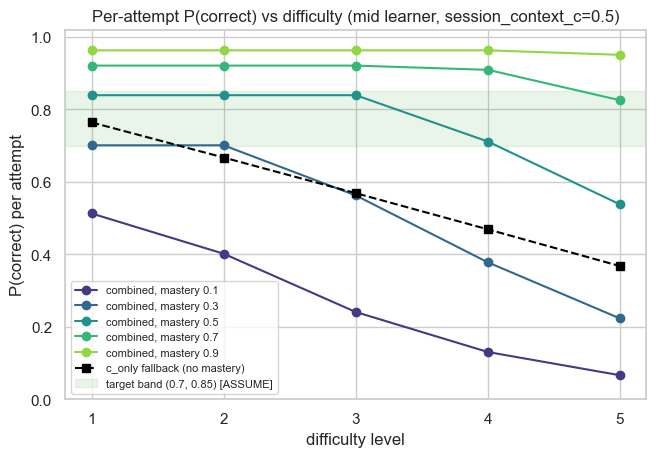

P flat while d_norm<=mastery: True | last flat level per mastery: {0.1: 1, 0.3: 2, 0.5: 3, 0.7: 3, 0.9: 4}
non-increasing in difficulty for every mastery: True | fallback strictly decreasing: True
fallback_mode_p_correct signature: (config: 'FallbackOutcomeConfig', difficulty_level: 'int', challenge_tolerance: 'float', session_context_c: 'float', off_day_indicator: 'bool') -> 'float'
component_c_generator/behaviour/outcome_model.py:  43      difficulty_norm = (difficulty_level - 1) / 4.0
component_c_generator/behaviour/outcome_model.py:  44      challenge_gap = difficulty_norm - selected_skill_mastery
component_c_generator/behaviour/outcome_model.py:  45      logit_correct = (
component_c_generator/behaviour/outcome_model.py:  46          coefficients.beta0
component_c_generator/behaviour/outcome_model.py:  47          + coefficients.beta_mastery * selected_skill_mastery
component_c_generator/behaviour/outcome_model.py:  48          - coefficients.beta_gap * max(0.0, challenge_gap)
com

In [5]:
MASTERIES = [0.1, 0.3, 0.5, 0.7, 0.9]
LEVELS = [1, 2, 3, 4, 5]
rows = []
for m in MASTERIES:
    for d in LEVELS:
        rows.append(dict(curve=f"combined m={m}", mastery=m, difficulty=d,
                         d_norm=(d - 1) / 4, gap=max(0.0, (d - 1) / 4 - m),
                         p_correct=combined_mode_p_correct(GP.outcome, d, m, TOL, SESSION_CTX, False)))
for d in LEVELS:
    rows.append(dict(curve="c_only fallback", mastery=np.nan, difficulty=d, d_norm=(d - 1) / 4, gap=np.nan,
                     p_correct=fallback_mode_p_correct(GP.fallback_outcome, d, TOL, SESSION_CTX, False)))
P = pd.DataFrame(rows)
wide = P.pivot(index="curve", columns="difficulty", values="p_correct").round(4)
display(wide)
save_table(P, "p_correct_by_difficulty")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
pal = sns.color_palette("viridis", len(MASTERIES))
for c, m in zip(pal, MASTERIES):
    s = P[P.curve == f"combined m={m}"]
    ax.plot(s.difficulty, s.p_correct, marker="o", color=c, label=f"combined, mastery {m}")
s = P[P.curve == "c_only fallback"]
ax.plot(s.difficulty, s.p_correct, marker="s", color="black", ls="--", label="c_only fallback (no mastery)")
ax.axhspan(*cfg.TARGET_BAND, color="tab:green", alpha=0.10, label=f"target band {cfg.TARGET_BAND} [ASSUME]")
ax.set_xticks(LEVELS); ax.set_xlabel("difficulty level"); ax.set_ylabel("P(correct) per attempt")
ax.set_title("Per-attempt P(correct) vs difficulty (mid learner, session_context_c=0.5)")
ax.legend(fontsize=8, loc="lower left"); ax.set_ylim(0, 1.02)
save_fig(fig, "p_correct_by_difficulty"); plt.show()

# analytical checks
flat_ok, falls_ok = True, True
knee = {}
for m in MASTERIES:
    p = P[P.curve == f"combined m={m}"].sort_values("difficulty").p_correct.to_numpy()
    d_norm = (np.array(LEVELS) - 1) / 4
    below = d_norm <= m
    flat_ok &= bool(np.allclose(p[below], p[0]))                   # no change while d_norm <= mastery
    falls_ok &= bool(np.all(np.diff(p[~below | (np.arange(5) == np.argmax(~below) - 1)]) <= 1e-12))
    knee[m] = int(np.max(np.array(LEVELS)[below])) if below.any() else 0
fb = P[P.curve == "c_only fallback"].sort_values("difficulty").p_correct.to_numpy()
CHECKS["p_flat_while_difficulty_le_mastery"] = flat_ok
CHECKS["p_nonincreasing_in_difficulty"] = bool(all(np.all(np.diff(P[P.curve == f'combined m={m}'].sort_values('difficulty').p_correct) <= 1e-12) for m in MASTERIES))
CHECKS["fallback_strictly_decreasing"] = bool(np.all(np.diff(fb) < 0))
print("P flat while d_norm<=mastery:", flat_ok, "| last flat level per mastery:", knee)
print("non-increasing in difficulty for every mastery:", CHECKS["p_nonincreasing_in_difficulty"], "| fallback strictly decreasing:", CHECKS["fallback_strictly_decreasing"])
# does mastery matter at all in fallback? (the function has no mastery argument)
print("fallback_mode_p_correct signature:", inspect.signature(fallback_mode_p_correct))
src("component_c_generator/behaviour/outcome_model.py", 43, 52)

### Findings — step 2


- Combined mode, per-attempt P(correct) at mastery 0.5: **0.8389** at levels 1–3, **0.7109** at level 4, **0.5374** at level 5. At mastery 0.9 it is 0.9627 for levels 1–4 and 0.9503 at level 5. At mastery 0.1 it starts at 0.5125 and falls to 0.0660.
- The curve is **flat while `d_norm = (d−1)/4 ≤ mastery`** (asserted for all five masteries) and non-increasing afterwards (`outcome_model.py:43-48`: the gap term is `max(0, d_norm − mastery)`). The last flat level is 1 / 2 / 3 / 3 / 4 for mastery 0.1 / 0.3 / 0.5 / 0.7 / 0.9.
- c_only fallback (`outcome_model.py:68`): **0.7638 → 0.6669 → 0.5685 → 0.4686 → 0.3672**, strictly decreasing, no mastery argument at all (signature printed).
- **Consequence for the target band [0.70, 0.85] [ASSUME].** For the mid learner the band is unreachable at *any* difficulty when mastery is 0.1 (max P = 0.5125) or 0.9 (min P = 0.9503). At mastery 0.7 only level 5 (0.8249) is in the band. At mastery 0.5 levels 1–4 are in the band; at 0.3 only levels 1–2 are (0.7006). A reward built on band-fit therefore cannot be maximised for the extremes. This comes straight from the formula, with no simulation.

## 3. What responds to difficulty?

Trace table first (producer → consumer, `file:line`), then an empirical probe: `generate_task_gameplay` at each
difficulty level, **2,000 seeded tasks per level** (200 learners-ids × 10 task slots), mid learner, combined mode,
mastery 0.5. The same seed lineages are used at every level (common random numbers), so a quantity that does not
depend on difficulty is *exactly* identical across levels.

In [6]:
trace = pd.DataFrame([
 ("P(correct) per attempt", "direct",
  "session.py:216-230 / selector -> task_instance.difficulty_level; attempt_loop.py:178-187 passes it to outcome_model.py:43-48 (combined: -beta_gap*max(0, d_norm - mastery)) or outcome_model.py:68 (c_only: base_probability_by_difficulty[d-1]); sampled at attempt_loop.py:266",
  "Combined: only when d_norm > mastery. c_only: every level."),
 ("number of attempts", "indirect-via-errors",
  "p fixed per task (attempt_loop.py:178-187); loop attempt_loop.py:193-303 repeats until a correct answer (L279-281) or cap (L285-291, max_attempts=10)",
  "Geometric in P(correct); difficulty acts only through P(correct)."),
 ("latency", "direct",
  "latency.py:43 difficulty_shift = 0.06*(d-3) -> L47-54 log_latency; called at attempt_loop.py:253-256; clock advanced L262",
  "Weak: +-0.12 log-units across levels 1..5."),
 ("timeout (no response)", "direct",
  "latency.py:57-58 raw_sec >= 90 s -> attempt_loop.py:257-260 quit(timeout_no_response)",
  "Direct through latency but vanishingly small (see timeout table below)."),
 ("quit_after_error", "indirect-via-errors",
  "decisions.py:28-37 takes (consecutive_error_max, persistence) only - no difficulty argument; called attempt_loop.py:296-300",
  "Rises with the error streak, which is driven by P(correct)."),
 ("quit_without_recent_error", "none",
  "attempt_loop.py:203-206, constant config.quit.quit_without_recent_error_probability (0.01), first attempt only",
  "Independent of difficulty, mastery, errors."),
 ("skip", "none", "attempt_loop.py:198-201, constant config.quit.skip_probability (0.02), first attempt only", "Independent of everything."),
 ("technical issue", "none", "attempt_loop.py:209-213, constant 0.01 per attempt", "Per-attempt: more attempts -> more exposure (second order)."),
 ("pauses (learner / technical)", "none", "attempt_loop.py:215-233, constants 0.08 / 0.02 per attempt", "Independent of difficulty."),
 ("scaffold request / level", "indirect-via-errors",
  "request: attempt_loop.py:246-250 constant 0.10; level decided attempt_loop.py:239-245 from consecutive_errors", "Level follows the error streak."),
], columns=["quantity", "class", "producer -> consumer trace (file:line)", "note"])
display(trace)
save_table(trace, "difficulty_response_trace")
for rel, a, b in [("component_c_generator/behaviour/attempt_loop.py", 196, 213), ("component_c_generator/behaviour/attempt_loop.py", 293, 300)]:
    src(rel, a, b); print()

,quantity,class,producer -> consumer trace (file:line),note
0,P(correct) per attempt,direct,session.py:216-230 / selector -> task_instance.difficulty_level; attempt_loop.py:178-187 passes it to outcome_model.py:43-48 (combined: ...,Combined: only when d_norm > mastery. c_only: every level.
1,number of attempts,indirect-via-errors,"p fixed per task (attempt_loop.py:178-187); loop attempt_loop.py:193-303 repeats until a correct answer (L279-281) or cap (L285-291, max...",Geometric in P(correct); difficulty acts only through P(correct).
2,latency,direct,latency.py:43 difficulty_shift = 0.06*(d-3) -> L47-54 log_latency; called at attempt_loop.py:253-256; clock advanced L262,Weak: +-0.12 log-units across levels 1..5.
3,timeout (no response),direct,latency.py:57-58 raw_sec >= 90 s -> attempt_loop.py:257-260 quit(timeout_no_response),Direct through latency but vanishingly small (see timeout table below).
4,quit_after_error,indirect-via-errors,"decisions.py:28-37 takes (consecutive_error_max, persistence) only - no difficulty argument; called attempt_loop.py:296-300","Rises with the error streak, which is driven by P(correct)."
5,quit_without_recent_error,none,"attempt_loop.py:203-206, constant config.quit.quit_without_recent_error_probability (0.01), first attempt only","Independent of difficulty, mastery, errors."
6,skip,none,"attempt_loop.py:198-201, constant config.quit.skip_probability (0.02), first attempt only",Independent of everything.
7,technical issue,none,"attempt_loop.py:209-213, constant 0.01 per attempt",Per-attempt: more attempts -> more exposure (second order).
8,pauses (learner / technical),none,"attempt_loop.py:215-233, constants 0.08 / 0.02 per attempt",Independent of difficulty.
9,scaffold request / level,indirect-via-errors,request: attempt_loop.py:246-250 constant 0.10; level decided attempt_loop.py:239-245 from consecutive_errors,Level follows the error streak.


component_c_generator/behaviour/attempt_loop.py: 196          # --- pre-attempt checks (only meaningful before the first submitted attempt) ---
component_c_generator/behaviour/attempt_loop.py: 197          if attempt_index == 1:
component_c_generator/behaviour/attempt_loop.py: 198              skip_rng = _rng(gseeds.skip_lineage(attempt))
component_c_generator/behaviour/attempt_loop.py: 199              if _bernoulli(skip_rng, config.quit.skip_probability):
component_c_generator/behaviour/attempt_loop.py: 200                  builder.emit("game_task_skipped", attempt, terminal_reason="skipped")
component_c_generator/behaviour/attempt_loop.py: 201                  return GameplayResult(events=tuple(builder.events))
component_c_generator/behaviour/attempt_loop.py: 202  
component_c_generator/behaviour/attempt_loop.py: 203              quit_early_rng = _rng(gseeds.quit_lineage(attempt))
component_c_generator/behaviour/attempt_loop.py: 204              if _bernoulli(quit_early_rng, config.

In [7]:
GRADE = 2
TIDS = [t for t in SUPPORTED if CATALOGUE.by_id(t).is_eligible_for_grade(GRADE)]
SM = SeedManager(cfg.RANDOM_SEED)
N_IDS, TASKS_PER = 200, 10          # 2,000 tasks per level

def probe(level, mastery, mode="combined", local=None, n_ids=N_IDS, tasks_per=TASKS_PER, keep_summaries=False):
    rows, sums = [], []
    for s in range(1, n_ids + 1):
        sid = f"STU-{s:04d}"; csid = f"{sid}-C-001"
        for j in range(1, tasks_per + 1):
            lin = SM.task_opportunity(sid, 1, 1, j)
            tpl = CATALOGUE.by_id(TIDS[(s * tasks_per + j) % len(TIDS)])
            ti = build_task_instance(template=tpl, seed_lineage=lin, grade=GRADE, difficulty_level=level, student_id=sid,
                                     c_session_id=csid, task_index=j, catalogue_version=CATALOGUE.catalogue_version, config=GEN)
            res = generate_task_gameplay(
                task_instance=ti, student_id=sid, intervention_session_id=f"{sid}-I-001", c_session_id=csid, task_index=j,
                session_mode=mode, selected_skill_mastery=(mastery if mode == "combined" else None),
                local_state=local or MID, session_context_c=SESSION_CTX, off_day_indicator=False, stop_signal_active=False,
                gameplay_process_lineage=SM.gameplay_process(sid, 1, 1, j, 1, 1), config=GP, scaffold_config=SCAF,
                safety_forces_recovery=False)
            sm_ = derive_task_opportunity_summary(res.events)
            rows.append(dict(level=level, completed=sm_.task_completed, correct_task=sm_.correct_task,
                             first_attempt_correct=sm_.first_attempt_correct, attempts=sm_.total_attempts,
                             quit=sm_.task_quit, quit_after_error=sm_.quit_after_error, skipped=sm_.task_skipped,
                             technical=sm_.technical_issue, terminal=sm_.terminal_reason, latency=sm_.task_latency_sec,
                             scaffolds=sm_.scaffold_count, err_run=sm_.consecutive_error_max_within_task))
            if keep_summaries:
                sums.append(sm_)
    df = pd.DataFrame(rows)
    return (df, sums) if keep_summaries else df

def level_table(raw):
    r = raw.copy()
    r["first_f"] = r.first_attempt_correct.map({True: 1.0, False: 0.0})      # None (no attempt) -> NaN
    r["att_pos"] = r.attempts.where(r.attempts > 0)
    r["lat_done"] = r.latency.where(r.completed)
    r["eventual"] = (r.correct_task == True).astype(float)
    r["qae"] = (r.quit_after_error == True).astype(float)
    r["timeout"] = (r.terminal == "timeout_no_response").astype(float)
    g = r.groupby("level")
    return pd.DataFrame({
        "n_tasks": g.size(), "n_attempted": g.first_f.count(),
        "completed": g.completed.mean(), "eventual_correct": g.eventual.mean(),
        "first_attempt_correct": g.first_f.mean(), "mean_attempts": g.att_pos.mean(), "mean_err_run": g.err_run.mean(),
        "quit_after_error": g.qae.mean(), "quit_any": g.quit.mean(), "skipped": g.skipped.mean(),
        "technical": g.technical.mean(), "timeout": g.timeout.mean(), "mean_latency_s": g.lat_done.mean(),
        "mean_scaffolds": g.scaffolds.mean(),
    })

def nominal_p(mode, mastery, d):
    if mode == "combined":
        return combined_mode_p_correct(GP.outcome, d, mastery, TOL, SESSION_CTX, False)
    return fallback_mode_p_correct(GP.fallback_outcome, d, TOL, SESSION_CTX, False)

def realized_vs_nominal(T, mode, mastery):
    rows = []
    for d in LEVELS:
        p, n, obs = nominal_p(mode, mastery, d), int(T.loc[d, "n_attempted"]), float(T.loc[d, "first_attempt_correct"])
        rows.append(dict(mode=mode, mastery=mastery, level=d, n_attempted=n, nominal_p=p, realized_first_attempt=obs,
                         diff=obs - p, z=(obs - p) / math.sqrt(p * (1 - p) / n)))
    R = pd.DataFrame(rows)
    pooled_z = float(((R.realized_first_attempt - R.nominal_p) * R.n_attempted).sum() / math.sqrt((R.n_attempted * R.nominal_p * (1 - R.nominal_p)).sum()))
    return R, pooled_z

raws, SUMS5 = [], None
for lv in LEVELS:
    r, sm_list = probe(lv, 0.5, keep_summaries=True)
    raws.append(r)
    if lv == 5:
        SUMS5 = sm_list
RAW3 = pd.concat(raws, ignore_index=True)
T3 = level_table(RAW3)
display(T3.round(4))
save_table(T3.reset_index(), "outcomes_by_difficulty")

mix = (RAW3.groupby("level").terminal.value_counts(normalize=True).unstack(fill_value=0).round(4))
print("\nterminal_reason mix by level:"); display(mix)
save_table(mix.reset_index(), "terminal_reason_mix_by_difficulty")

# c_only probe (fallback outcome model) on the same seeds, and nominal-vs-realized first-attempt correctness
RAW3C = pd.concat([probe(lv, None, mode="c_only") for lv in LEVELS], ignore_index=True)
T3C = level_table(RAW3C)
print("\nc_only (fallback model) outcomes by level:"); display(T3C.round(4)); save_table(T3C.reset_index(), "outcomes_by_difficulty_c_only")
RV1, z1 = realized_vs_nominal(T3, "combined", 0.5)
RV2, z2 = realized_vs_nominal(T3C, "c_only", None)
RV = pd.concat([RV1, RV2], ignore_index=True)
print("\nnominal P(correct) (outcome_model) vs REALIZED first-attempt correctness (after choose_action + evaluate):")
display(RV.round(4)); save_table(RV, "nominal_vs_realized_first_attempt")
CHECKS["realized_minus_nominal_combined_m0.5"] = float((RV1.realized_first_attempt - RV1.nominal_p).mean())
CHECKS["pooled_z_combined_m0.5"], CHECKS["pooled_z_c_only"] = z1, z2
CHECKS["realized_minus_nominal_c_only"] = float((RV2.realized_first_attempt - RV2.nominal_p).mean())
print(f"mean realized-nominal: combined {CHECKS['realized_minus_nominal_combined_m0.5']:+.4f} (pooled z={z1:.2f}); c_only {CHECKS['realized_minus_nominal_c_only']:+.4f} (pooled z={z2:.2f})")
src("component_c_generator/behaviour/action_provider.py", 1, 12)

,n_tasks,n_attempted,completed,eventual_correct,first_attempt_correct,mean_attempts,mean_err_run,quit_after_error,quit_any,skipped,technical,timeout,mean_latency_s,mean_scaffolds
level,,,,,,,,,,,,,,
1,2000,1927,0.9425,0.9425,0.8531,1.1505,0.1660,0.0190,0.0370,0.0205,0.010,0.0,10.6251,0.1065
2,2000,1927,0.9425,0.9425,0.8531,1.1505,0.1660,0.0190,0.0370,0.0205,0.010,0.0,11.2821,0.1065
3,2000,1927,0.9425,0.9425,0.8531,1.1505,0.1660,0.0190,0.0370,0.0205,0.010,0.0,11.9797,0.1065
4,2000,1927,0.9150,0.9150,0.7260,1.3181,0.3550,0.0435,0.0645,0.0205,0.013,0.0,12.8063,0.1250
5,2000,1927,0.8540,0.8540,0.5537,1.6238,0.7105,0.1005,0.1255,0.0205,0.017,0.0,13.4808,0.1525



terminal_reason mix by level:


terminal,completed_correct,quit_after_error,quit_without_recent_error,skipped,technical_issue
level,,,,,
1,0.9425,0.0190,0.008,0.0205,0.010
2,0.9425,0.0190,0.008,0.0205,0.010
3,0.9425,0.0190,0.008,0.0205,0.010
4,0.9150,0.0435,0.008,0.0205,0.013
5,0.8540,0.1005,0.008,0.0205,0.017



c_only (fallback model) outcomes by level:


,n_tasks,n_attempted,completed,eventual_correct,first_attempt_correct,mean_attempts,mean_err_run,quit_after_error,quit_any,skipped,technical,timeout,mean_latency_s,mean_scaffolds
level,,,,,,,,,,,,,,
1,2000,1927,0.9270,0.9270,0.7763,1.2392,0.2670,0.0335,0.0525,0.0205,0.0110,0.0,10.6575,0.1205
2,2000,1927,0.9030,0.9030,0.6809,1.3887,0.4350,0.0545,0.0765,0.0205,0.0140,0.0,11.3684,0.1340
3,2000,1927,0.8685,0.8685,0.5864,1.5599,0.6345,0.0860,0.1110,0.0205,0.0170,0.0,12.0023,0.1480
4,2000,1927,0.8150,0.8150,0.4826,1.7613,0.8820,0.1390,0.1645,0.0205,0.0175,0.0,12.7295,0.1660
5,2000,1927,0.7500,0.7500,0.3819,2.0322,1.2080,0.2020,0.2295,0.0205,0.0195,0.0,13.4785,0.1920



nominal P(correct) (outcome_model) vs REALIZED first-attempt correctness (after choose_action + evaluate):


C:\Users\Yasindu\AppData\Local\Temp\ipykernel_15364\285458441.py:86: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  RV = pd.concat([RV1, RV2], ignore_index=True)


,mode,mastery,level,n_attempted,nominal_p,realized_first_attempt,diff,z
0,combined,0.5,1,1927,0.8389,0.8531,0.0142,1.7014
1,combined,0.5,2,1927,0.8389,0.8531,0.0142,1.7014
2,combined,0.5,3,1927,0.8389,0.8531,0.0142,1.7014
3,combined,0.5,4,1927,0.7109,0.7260,0.0150,1.4573
4,combined,0.5,5,1927,0.5374,0.5537,0.0163,1.4334
5,c_only,NaN,1,1927,0.7638,0.7763,0.0125,1.2959
6,c_only,NaN,2,1927,0.6669,0.6809,0.0140,1.3026
7,c_only,NaN,3,1927,0.5685,0.5864,0.0179,1.5882
8,c_only,NaN,4,1927,0.4686,0.4826,0.0140,1.2308
9,c_only,NaN,5,1927,0.3672,0.3819,0.0147,1.3379


mean realized-nominal: combined +0.0148 (pooled z=3.51); c_only +0.0146 (pooled z=3.02)
component_c_generator/behaviour/action_provider.py:   1  """``ActionProvider`` (C3 §7.1/§7.2) -- the synthetic generator's action-generation seam (D2).
component_c_generator/behaviour/action_provider.py:   2  
component_c_generator/behaviour/action_provider.py:   3  ``choose_action`` generates a real, syntactically valid candidate action from the template's
component_c_generator/behaviour/action_provider.py:   4  own ``valid_action_space`` shape. It is deliberately biased toward a target outcome
component_c_generator/behaviour/action_provider.py:   5  (``target_correct``) using ONLY the instance's own ``correct_answer_payload`` -- but it never
component_c_generator/behaviour/action_provider.py:   6  computes or asserts correctness itself: the returned action is always passed to the committed
component_c_generator/behaviour/action_provider.py:   7  C2.1 ``evaluate()`` (the sole correctness authority,

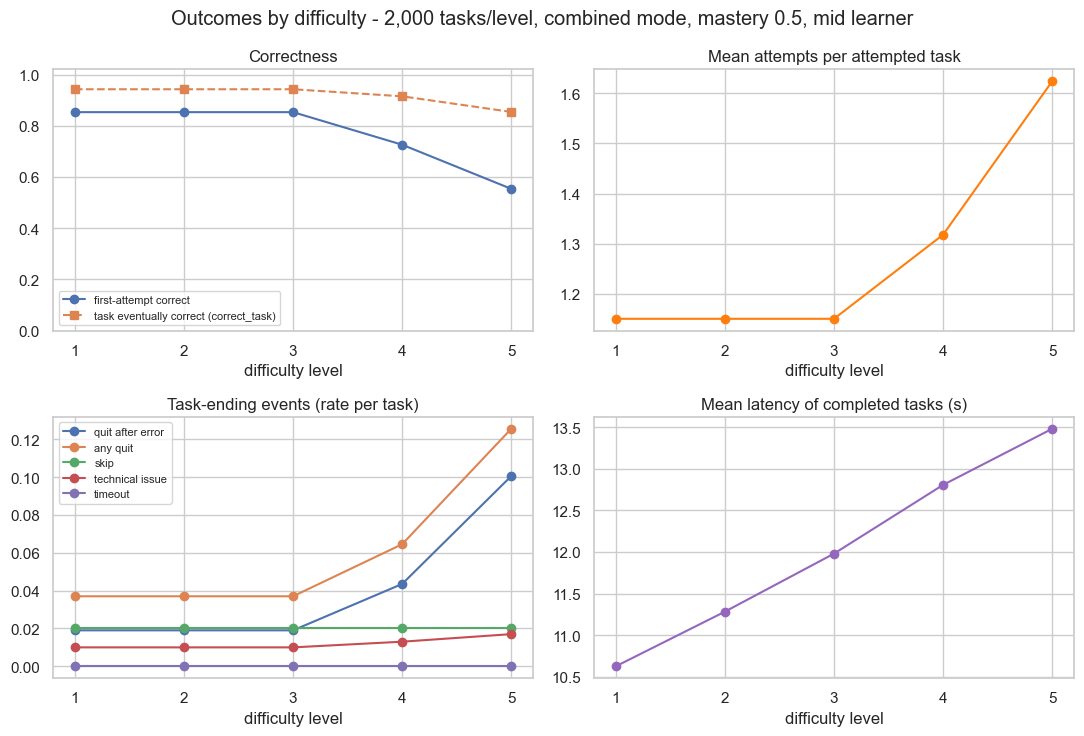

   skipped identical task-by-task across levels: True
quit_without_recent_error identical task-by-task across levels: True
share of COMPLETED tasks with correct_task=True: 1.0


,level,mu_log,median_latency_s,z_to_timeout,p_timeout_per_attempt
0,1,2.28,9.78,5.55,1.432241e-08
1,2,2.34,10.38,5.40,3.340894e-08
2,3,2.40,11.02,5.25,7.624629e-08
3,4,2.46,11.70,5.10,1.702542e-07
4,5,2.52,12.43,4.95,3.719757e-07


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
ax.plot(T3.index, T3.first_attempt_correct, "o-", label="first-attempt correct")
ax.plot(T3.index, T3.eventual_correct, "s--", label="task eventually correct (correct_task)")
ax.set_title("Correctness"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8)
ax = axes[0, 1]
ax.plot(T3.index, T3.mean_attempts, "o-", color="tab:orange"); ax.set_title("Mean attempts per attempted task")
ax = axes[1, 0]
for c, lab in [("quit_after_error", "quit after error"), ("quit_any", "any quit"), ("skipped", "skip"), ("technical", "technical issue"), ("timeout", "timeout")]:
    ax.plot(T3.index, T3[c], "o-", label=lab)
ax.set_title("Task-ending events (rate per task)"); ax.legend(fontsize=8)
ax = axes[1, 1]
ax.plot(T3.index, T3.mean_latency_s, "o-", color="tab:purple"); ax.set_title("Mean latency of completed tasks (s)")
for a in axes.ravel():
    a.set_xticks(LEVELS); a.set_xlabel("difficulty level")
fig.suptitle("Outcomes by difficulty - 2,000 tasks/level, combined mode, mastery 0.5, mid learner")
fig.tight_layout(); save_fig(fig, "outcomes_by_difficulty"); plt.show()

# CRN equality: quantities that should not depend on difficulty are exactly equal across levels
def identical_across_levels(col):
    piv = RAW3.assign(i=RAW3.groupby("level").cumcount()).pivot(index="i", columns="level", values=col)
    return bool((piv.nunique(axis=1) == 1).all())
for col in ["skipped"]:
    print(f"{col:>10} identical task-by-task across levels:", identical_across_levels(col))
CHECKS["skip_identical_across_levels"] = identical_across_levels("skipped")
# quit_without_recent_error happens before any attempt -> compare per task
qw = (RAW3.terminal == "quit_without_recent_error").astype(int)
RAW3["_qw"] = qw
piv = RAW3.assign(i=RAW3.groupby("level").cumcount()).pivot(index="i", columns="level", values="_qw")
CHECKS["quit_without_error_identical_across_levels"] = bool((piv.nunique(axis=1) == 1).all())
print("quit_without_recent_error identical task-by-task across levels:", CHECKS["quit_without_error_identical_across_levels"])
CHECKS["first_attempt_correct_d1_to_d5_drop"] = float(T3.first_attempt_correct.iloc[0] - T3.first_attempt_correct.iloc[-1])
CHECKS["eventual_correct_rate_range"] = (float(T3.eventual_correct.min()), float(T3.eventual_correct.max()))
CHECKS["share_completed_tasks_correct"] = float((RAW3[RAW3.completed].correct_task == True).mean())
print("share of COMPLETED tasks with correct_task=True:", round(CHECKS["share_completed_tasks_correct"], 4))

# analytic timeout probability under the lognormal latency model (latency.py:43-58)
from scipy.stats import norm
L = GP.latency
tr = []
for d in LEVELS:
    mu = L.location_mu + L.difficulty_shift_per_level * (d - 3) + MID.c_game_fluency_baseline + L.session_shift_weight * SESSION_CTX
    z = (math.log(L.timeout_threshold_sec) - mu) / L.scale_sigma
    tr.append(dict(level=d, mu_log=round(mu, 3), median_latency_s=round(math.exp(mu), 2), z_to_timeout=round(z, 2), p_timeout_per_attempt=norm.sf(z)))
TO = pd.DataFrame(tr); display(TO)
save_table(TO, "timeout_probability")
CHECKS["max_timeout_prob_per_attempt"] = float(TO.p_timeout_per_attempt.max())

### Findings — step 3


**Trace + probe (2,000 tasks per level, combined, mastery 0.5, mid learner, same seeds at every level):**

| quantity | level 1 → 5 | class |
|---|---|---|
| first-attempt correct | 0.8531, 0.8531, 0.8531, **0.7260**, **0.5537** | **direct** (via P(correct); only above d_norm = mastery) |
| mean attempts | 1.1505 (×3), 1.3181, 1.6238 | indirect (geometric in P) |
| quit_after_error | 0.0190 (×3), 0.0435, **0.1005** | indirect-via-errors (`decisions.py:28-37` has no difficulty argument) |
| any quit | 0.0370 → 0.1255 | indirect |
| task eventually correct (= completed) | 0.9425 (×3), 0.9150, 0.8540 | indirect |
| latency (s) | 10.63, 11.28, 11.98, 12.81, 13.48 (+27%) | direct but weak (`latency.py:43`) |
| timeout | 0 observed; analytic 1.4e-8 … 3.7e-7 per attempt | direct, negligible |
| skip | 0.0205 at every level, **identical task-by-task** | none |
| quit_without_recent_error | 0.008 at every level, **identical task-by-task** | none |
| technical issue | 0.010 → 0.017 (only because more attempts mean more exposure) | none (second order) |

- **c_only** (same seeds): first-attempt correct 0.7763, 0.6809, 0.5864, 0.4826, 0.3819; quit_after_error 0.0335 → **0.2020**; completed 0.927 → 0.750.
- **Retries make `correct_task` uninformative.** `max_attempts` = 10 (`gameplay_config.py:239`), so **the share of completed tasks with `correct_task=True` is 1.000**. Eventual correctness equals the completion rate, and difficulty acts mainly on *first-attempt* correctness and attempts. This matters for §6 and §11.
- **Realized vs nominal.** Realized first-attempt correctness is higher than the nominal P at every level. The mean excess is **+0.0148** (combined) and **+0.0146** (c_only), 1.2–1.8 points per level. The per-level z-scores are 1.2–1.7. The pooled z of 3.5 / 3.0 is overstated because the levels share seeds. The documented cause is `action_provider.py:7-10`: a "wrong" draw can still evaluate as correct. It is small, but NB03's calibration compares realized rates, not nominal ones.

## 4. Is there any penalty for a too-easy task?

Hypothesis (master plan §6, expected finding): **no**. R0 requires the full chain, so we check every place a
too-easy task could be punished: (a) the outcome model, (b) the quit / skip / pause models, (c) the learner's
engagement trait, (d) the aggregate → composites → learner-state path, (e) the policy, safety and reward code.

In [9]:
print("(a) outcome model: the gap term is clipped at zero, so an easier-than-mastery task cannot lower P(correct)")
src("component_c_generator/behaviour/outcome_model.py", 43, 49)

print("\n(c) consumers of the engagement trait c_engagement_propensity (anywhere in component_c_generator):")
hits_eng = grep_yass(r"c_engagement_propensity")
display(pd.DataFrame(hits_eng, columns=["file", "line", "text"]))
consumers = [h for h in hits_eng if not h[0].startswith("component_c_generator/models/") and "pilot_cohort" not in h[0]]
CHECKS["engagement_propensity_has_consumer"] = bool(consumers)

print("\n(d)+(e) every CODE identifier mentioning 'difficulty' in composites/*, aggregation/derive.py and rewards.py (AST, docstrings excluded):")
rows = []
for rel in sorted([p.relative_to(cfg.YASS_IMPL_ROOT).as_posix() for p in (cfg.YASS_IMPL_ROOT / "component_c_generator" / "composites").glob("*.py")]
                  + ["component_c_generator/aggregation/derive.py", "component_c_generator/rewards.py"]):
    tree = ast.parse((cfg.YASS_IMPL_ROOT / rel).read_text(encoding="utf-8"))
    for node in ast.walk(tree):
        nm = (node.id if isinstance(node, ast.Name) else node.attr if isinstance(node, ast.Attribute)
              else node.arg if isinstance(node, ast.arg) else None)
        if nm and "difficulty" in nm:
            rows.append((rel, node.lineno, nm))
D = pd.DataFrame(sorted(set(rows)), columns=["file", "line", "identifier"])
display(D)
print("identifiers per file:", D.groupby("file").size().to_dict(), "| rewards.py hits:", int((D.file.str.endswith("rewards.py")).sum()))
CHECKS["rewards_py_difficulty_hits"] = int((D.file.str.endswith("rewards.py")).sum())
CHECKS["difficulty_identifiers_beyond_bookkeeping"] = sorted(set(D.identifier) - {"difficulty_floor_hits", "difficulty_after", "difficulty_before", "current_difficulty_level", "difficulty_trend"})
print("identifiers beyond floor-hits / trajectory bookkeeping:", CHECKS["difficulty_identifiers_beyond_bookkeeping"])
src("component_c_generator/aggregation/derive.py", 144, 148)
src("component_c_generator/composites/engagement_frustration.py", 104)

(a) outcome model: the gap term is clipped at zero, so an easier-than-mastery task cannot lower P(correct)
component_c_generator/behaviour/outcome_model.py:  43      difficulty_norm = (difficulty_level - 1) / 4.0
component_c_generator/behaviour/outcome_model.py:  44      challenge_gap = difficulty_norm - selected_skill_mastery
component_c_generator/behaviour/outcome_model.py:  45      logit_correct = (
component_c_generator/behaviour/outcome_model.py:  46          coefficients.beta0
component_c_generator/behaviour/outcome_model.py:  47          + coefficients.beta_mastery * selected_skill_mastery
component_c_generator/behaviour/outcome_model.py:  48          - coefficients.beta_gap * max(0.0, challenge_gap)
component_c_generator/behaviour/outcome_model.py:  49          + coefficients.beta_tolerance * (challenge_tolerance - 0.5)

(c) consumers of the engagement trait c_engagement_propensity (anywhere in component_c_generator):


,file,line,text
0,component_c_generator/models/learner_state.py,30,"``c_challenge_tolerance``, ``c_engagement_propensity``) are population-neutral C-local"
1,component_c_generator/models/learner_state.py,40,c_engagement_propensity: Probability
2,component_c_generator/pipeline/pilot_cohort.py,142,"c_engagement_propensity=0.3 + 0.4 * (learner_index % 5) / 4.0,"



(d)+(e) every CODE identifier mentioning 'difficulty' in composites/*, aggregation/derive.py and rewards.py (AST, docstrings excluded):


,file,line,identifier
0,component_c_generator/aggregation/derive.py,64,min_completed_tasks_for_difficulty_trend
1,component_c_generator/aggregation/derive.py,66,difficulty_after
2,component_c_generator/aggregation/derive.py,66,difficulty_before
3,component_c_generator/aggregation/derive.py,144,difficulty_floor_hits
4,component_c_generator/aggregation/derive.py,147,difficulty_after
5,component_c_generator/aggregation/derive.py,165,current_difficulty_level
6,component_c_generator/aggregation/derive.py,165,difficulty_after
7,component_c_generator/aggregation/derive.py,167,current_difficulty_level
8,component_c_generator/aggregation/derive.py,169,_decide_difficulty_trend
9,component_c_generator/aggregation/derive.py,169,difficulty_trend


identifiers per file: {'component_c_generator/aggregation/derive.py': 13, 'component_c_generator/composites/engagement_frustration.py': 1, 'component_c_generator/composites/learner_state.py': 2} | rewards.py hits: 0
identifiers beyond floor-hits / trajectory bookkeeping: ['_decide_difficulty_trend', 'min_completed_tasks_for_difficulty_trend']
component_c_generator/aggregation/derive.py: 144      difficulty_floor_hits = sum(
component_c_generator/aggregation/derive.py: 145          1
component_c_generator/aggregation/derive.py: 146          for d in adaptation_decisions
component_c_generator/aggregation/derive.py: 147          if d.difficulty_after == 1
component_c_generator/aggregation/derive.py: 148          and (d.applied_action == "decrease_difficulty" or d.selected_action == "decrease_difficulty")
component_c_generator/composites/engagement_frustration.py: 104      floor_hit_component = _clamp01(aggregate.difficulty_floor_hits / 3)


In [10]:
# (b)+(empirical): at mastery 0.9, levels 1..4 are all "easier than or equal to mastery" (d_norm = 0, .25, .5, .75 <= .9)
EASY = pd.concat([probe(lv, 0.9) for lv in LEVELS], ignore_index=True)
T4 = level_table(EASY)
display(T4.round(4))
save_table(T4.reset_index(), "too_easy_probe_mastery_0.9")
cols = ["first_attempt_correct", "eventual_correct", "mean_attempts", "quit_after_error", "quit_any", "skipped", "technical", "timeout", "mean_scaffolds", "mean_err_run"]
d14 = T4.loc[1:4, cols]
CHECKS["mastery0.9_levels1to4_identical_outcomes"] = bool(np.allclose(d14.max() - d14.min(), 0, atol=1e-12))
latency_rel = float(T4.loc[4, "mean_latency_s"] / T4.loc[1, "mean_latency_s"])
CHECKS["latency_ratio_d4_over_d1_at_m0.9"] = latency_rel
print("\nlevels 1..4 identical on every non-latency outcome rate:", CHECKS["mastery0.9_levels1to4_identical_outcomes"])
print("mean latency d4/d1:", round(latency_rel, 3), "(latency.py:43 shift only; slower when harder, never penalising ease)")
# quit_after_error rate at the easiest vs the hardest level, for the same learner
print("quit_after_error  d1:", round(T4.loc[1, "quit_after_error"], 4), " d5:", round(T4.loc[5, "quit_after_error"], 4))

,n_tasks,n_attempted,completed,eventual_correct,first_attempt_correct,mean_attempts,mean_err_run,quit_after_error,quit_any,skipped,technical,timeout,mean_latency_s,mean_scaffolds
level,,,,,,,,,,,,,,
1,2000,1927,0.9610,0.9610,0.9663,1.0327,0.0340,0.0020,0.0185,0.0205,0.0085,0.0,10.6291,0.0935
2,2000,1927,0.9610,0.9610,0.9663,1.0327,0.0340,0.0020,0.0185,0.0205,0.0085,0.0,11.2863,0.0935
3,2000,1927,0.9610,0.9610,0.9663,1.0327,0.0340,0.0020,0.0185,0.0205,0.0085,0.0,11.9842,0.0935
4,2000,1927,0.9610,0.9610,0.9663,1.0327,0.0340,0.0020,0.0185,0.0205,0.0085,0.0,12.7253,0.0935
5,2000,1927,0.9585,0.9585,0.9538,1.0431,0.0465,0.0045,0.0210,0.0205,0.0085,0.0,13.4950,0.0960



levels 1..4 identical on every non-latency outcome rate: True
mean latency d4/d1: 1.197 (latency.py:43 shift only; slower when harder, never penalising ease)
quit_after_error  d1: 0.002  d5: 0.0045


### Findings — step 4


**Answer: no. Nothing in the generator penalises a task that is too easy** (R0 chain, each link checked):
1. *Outcome model* (`outcome_model.py:48`): `max(0.0, challenge_gap)`, so an easier-than-mastery task cannot lower P(correct).
2. *Probe at mastery 0.9* (levels 1–4 are all ≤ mastery): first-attempt correct **0.9663**, mean attempts 1.0327, quit_after_error 0.0020, skip 0.0205, technical 0.0085, scaffolds 0.0935 are **identical at levels 1, 2, 3 and 4** (asserted). Only latency moves (d4/d1 = **1.197**, slower when harder). Level 5, the only level above mastery, is worse: first-attempt 0.9538, quit_after_error 0.0045.
3. *Engagement trait*: `c_engagement_propensity` appears in 3 places in `component_c_generator`: the model field (`models/learner_state.py:40`), its docstring, and the pilot cohort producer (`pipeline/pilot_cohort.py:142`). It has **no consumer**. No boredom mechanism exists.
4. *Composites / aggregation / rewards*: the only difficulty-dependent quantity is `difficulty_floor_hits` (`aggregation/derive.py:144-148`), which counts decisions that hit **level 1 under downward pressure**, so it penalises tasks that are too *hard*. It feeds `engagement_frustration.py:104` and `learner_state.py:115`. There is no ceiling or "too easy" analogue, and `rewards.py` has **0** identifiers mentioning difficulty.
5. *Policy / safety*: no input or branch depends on "too easy" (section 7).

**Consequence:** in the unextended simulator the dominant strategy is "stay at the lowest difficulty" (highest P, fewest errors, lowest strain). Master plan §6's expectation is confirmed, and extension 6.1 (mastery growth with a fit term) is what creates a reason to go up. Without it, any agent will learn to keep the child at level 1.

## 5. Mastery dynamics: does C ever write to mastery?

Expected: C receives a `BToCMasteryPayload` per session and never writes mastery. This matters for master plan §2.3
point 2 (the data cannot show the causal effect of C difficulty on learning). Evidence: (a) an AST scan of every module for
stores to anything mastery-named, (b) the call order in the shared orchestrator, (c) an empirical before/after on a run.

In [11]:
# (a) AST scan: every assignment / augmented assignment / setattr / model_copy(update=...) touching a mastery-named target
def target_names(t):
    if isinstance(t, ast.Name): return [("name", t.id)]
    if isinstance(t, ast.Attribute): return [("attr", t.attr)]
    if isinstance(t, ast.Subscript): return [("subscript", ast.unparse(t))]
    if isinstance(t, (ast.Tuple, ast.List)): return [x for e in t.elts for x in target_names(e)]
    return []

stores = []
for root_dir in ["component_c_generator", "shared_orchestrator"]:
    for p in sorted((cfg.YASS_IMPL_ROOT / root_dir).rglob("*.py")):
        if "__pycache__" in p.parts: continue
        tree = ast.parse(p.read_text(encoding="utf-8"))
        rel = p.relative_to(cfg.YASS_IMPL_ROOT).as_posix()
        for node in ast.walk(tree):
            tgts = []
            if isinstance(node, ast.Assign): tgts = [x for t in node.targets for x in target_names(t)]
            elif isinstance(node, (ast.AugAssign, ast.AnnAssign)): tgts = target_names(node.target)
            for kind, nm in tgts:
                if "mastery" in nm.lower():
                    stores.append((rel, node.lineno, kind, nm, ast.unparse(node)[:110]))
            if isinstance(node, ast.Call):
                f = ast.unparse(node.func)
                txt = ast.unparse(node)
                if ("setattr" in f or f.endswith("model_copy")) and "mastery" in txt.lower():
                    stores.append((rel, node.lineno, "call", f, txt[:110]))
S = pd.DataFrame(stores, columns=["file", "line", "kind", "target", "statement"])
display(S)
save_table(S, "mastery_store_scan")
CHECKS["mastery_attribute_or_payload_writes"] = int(((S.kind != "name") & (S.kind != "subscript")).sum()) if len(S) else 0
CHECKS["mastery_store_hits_total"] = len(S)
print("attribute / subscript / setattr / model_copy stores touching mastery:", CHECKS["mastery_attribute_or_payload_writes"], "of", len(S), "hits")

,file,line,kind,target,statement
0,component_c_generator/gameplay_config.py,40,name,beta_mastery,beta_mastery: float = Field(allow_inf_nan=False)
1,component_c_generator/models/session.py,73,name,b_mastery_payload,b_mastery_payload: BToCMasteryPayload | None
2,component_c_generator/pipeline/evidence.py,32,name,_MASTERY_FIELD_BY_SKILL,"_MASTERY_FIELD_BY_SKILL = {'counting': 'mastery_counting', 'number_sense': 'mastery_number_sense', 'place_valu"
3,component_c_generator/pipeline/pilot.py,378,name,mastery_payload,"mastery_payload = fresh_mastery_payload(global_seed=cfg.global_seed, student_id=learner.student_id, session_in"
4,component_c_generator/pipeline/pilot_cohort.py,60,name,MASTERY_LEVEL_PROFILES,"MASTERY_LEVEL_PROFILES: Tuple[float, ...] = (0.05, 0.2, 0.4, 0.6, 0.8, 0.95)"
5,component_c_generator/pipeline/pilot_cohort.py,93,name,mastery_level,mastery_level: Optional[float]
6,component_c_generator/pipeline/pilot_cohort.py,175,name,mastery_level,mastery_level = learner_mastery_level if session_mode == 'combined' else None
7,component_c_generator/pipeline/pilot_cohort.py,212,name,mastery_level,"mastery_level = _mastery_level_for(global_seed, student_id)"
8,component_c_generator/pipeline/session.py,236,name,selected_skill_mastery,selected_skill_mastery: Optional[float] = None
9,component_c_generator/pipeline/session.py,238,name,selected_skill_mastery,"selected_skill_mastery = mastery_value_for_skill(mastery_payload, selected_skill)"


attribute / subscript / setattr / model_copy stores touching mastery: 0 of 26 hits


In [12]:
# (b) producer -> consumer trace
print("run_c_session: where the payload is consumed (parameter L125; read per task at L236-238; select_task L198-213)")
src("component_c_generator/pipeline/session.py", 125); src("component_c_generator/pipeline/session.py", 236, 238)
print("\nselect_task receives the same, unmodified payload:")
src("component_c_generator/pipeline/session.py", 207)
print("\nshared orchestrator: B sessions are produced for the WHOLE learner BEFORE any C session runs")
for a, b in [(261, 270)]:
    src("shared_orchestrator/session_loop.py", a, b)
print("\nwhat is handed to C each session, and what comes back (state carries no mastery):")
src("shared_orchestrator/session_loop.py", 208); src("shared_orchestrator/session_loop.py", 210); src("shared_orchestrator/session_loop.py", 193)
print("\nsecond mastery producer: the pilot harness fabricates B payloads without running B (inputs: seed, student, session index, a fixed level profile):")
src("component_c_generator/pipeline/pilot.py", 378, 383); src("component_c_generator/pipeline/pilot_cohort.py", 228, 233)
from component_c_generator.pipeline.session_state import CLearnerSessionState
print("\nCLearnerSessionState fields:", list(CLearnerSessionState.model_fields), "| extra:", CLearnerSessionState.model_config.get("extra"))
print("CLocalLearnerState mastery-like fields:", [f for f in CLocalLearnerState.model_fields if "mastery" in f] or "none")
from models.contracts import BToCMasteryPayload
print("BToCMasteryPayload.model_config:", dict(BToCMasteryPayload.model_config))
CHECKS["c_state_has_mastery_field"] = any("mastery" in f for f in list(CLearnerSessionState.model_fields) + list(CLocalLearnerState.model_fields))

run_c_session: where the payload is consumed (parameter L125; read per task at L236-238; select_task L198-213)
component_c_generator/pipeline/session.py: 125      mastery_payload: Optional[BToCMasteryPayload],
component_c_generator/pipeline/session.py: 236          selected_skill_mastery: Optional[float] = None
component_c_generator/pipeline/session.py: 237          if session_mode == "combined":
component_c_generator/pipeline/session.py: 238              selected_skill_mastery = mastery_value_for_skill(mastery_payload, selected_skill)

select_task receives the same, unmodified payload:
component_c_generator/pipeline/session.py: 207                  mastery_payload=mastery_payload,

shared orchestrator: B sessions are produced for the WHOLE learner BEFORE any C session runs
shared_orchestrator/session_loop.py: 261  def run_all_combined_for_learner(learner: SharedLearner, config: OrchestratorConfig) -> Tuple[CombinedSessionRecord, ...]:
shared_orchestrator/session_loop.py: 262      """S

In [13]:
# (c) empirical: run one combined session; compare payload and local state before/after
from datetime import date, datetime
from component_c_generator.pipeline.session import run_c_session
from component_c_generator.c_to_3.inputs import CToComponent3Provenance
FIXED_TIMESTAMP = datetime(2026, 7, 21, 12, 0, 0)   # fixed, as in the Yass test (no wall clock)

def mastery_payload(sid="STU-0001", values=None, session_no=3):
    skills = ["counting", "number_sense", "place_value", "addition", "subtraction", "multiplication", "division"]
    values = values or dict(zip(skills, [0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]))   # same values as the Yass pipeline test
    return BToCMasteryPayload(schema_version="2.1", student_id=sid, intervention_session_id=f"{sid}-I-001",
                              intervention_session_number=session_no, component_source="B",
                              **{f"mastery_{k}": v for k, v in values.items()})

def mapping_row(sid, session_no=3):
    return dict(schema_version="1.0", student_id=sid, intervention_session_id=f"{sid}-I-001",
                intervention_session_number=session_no, intervention_session_date=date(2026, 7, 21),
                b_session_id=f"{sid}-B-{session_no:03d}", c_session_id=f"{sid}-C-001", b_present=True, c_present=True)

def session_kwargs(sid="STU-0001", mode="combined", n_tasks=12, mastery=None, seed_manager=None, gameplay=None, safety=None,
                   local=None, session_no=3, grade=2, prior_state=None, **over):
    """Config recipe from tests/test_c_generator_phase_c6_0_pipeline.py:105-120 (_base_kwargs)."""
    combined = mode == "combined"
    kw = dict(
        seed_manager=seed_manager or SeedManager(cfg.RANDOM_SEED), student_id=sid, intervention_session_id=f"{sid}-I-001",
        intervention_session_number=session_no, c_session_index=1, c_session_id=f"{sid}-C-001", grade=grade,
        session_mode=mode, session_phase="mastery_driven" if combined else "c_only",
        mastery_payload=(mastery or mastery_payload(sid, session_no=session_no)) if combined else None,
        sessions_since_last_practice={}, local_state=local or MID, session_context_c=SESSION_CTX, off_day_indicator=False,
        prior_session_end_state=prior_state, max_task_opportunities=n_tasks, policy_mode="rule_based_baseline",
        catalogue=CATALOGUE, supported_template_ids=SUPPORTED, generation_config=GEN, gameplay_config=gameplay or GP,
        selection_config=SEL, policy_config=POL, safety_config=safety or SAFE, scaffold_config=SCAF, recovery_config=REC,
        evidence_window_config=EVW, aggregation_config=AGG,
        time_in_target_band_sec=100.0 if combined else 0.0, inactive_time_available=True,
        mapping_row=mapping_row(sid, session_no),
        provenance=CToComponent3Provenance(c_session_number=1, policy_version="v1", production_timestamp=FIXED_TIMESTAMP))
    kw.update(over)
    return kw

pay = mastery_payload(); loc = local_state()
pay_before, loc_before = pay.model_dump(), loc.model_dump()
res = run_c_session(**session_kwargs(mastery=pay, local=loc))
CHECKS["payload_unchanged_after_session"] = pay.model_dump() == pay_before
CHECKS["local_state_unchanged_after_session"] = loc.model_dump() == loc_before
print("B payload unchanged after a 12-task session  :", CHECKS["payload_unchanged_after_session"])
print("CLocalLearnerState unchanged after the session:", CHECKS["local_state_unchanged_after_session"])
print("tasks:", len(res.record.task_instances), "| difficulty trajectory:", [t.difficulty_level for t in res.record.task_instances])
print("skills practised:", [t.skill_id for t in res.record.task_instances])
try:
    pay.mastery_counting = 0.0
    print("payload is MUTABLE (assignment accepted)"); pay.mastery_counting = pay_before["mastery_counting"]
except Exception as e:
    print("payload is immutable:", type(e).__name__)

B payload unchanged after a 12-task session  : True
CLocalLearnerState unchanged after the session: True
tasks: 12 | difficulty trajectory: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
skills practised: ['subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction', 'subtraction']
payload is MUTABLE (assignment accepted)


### Findings — step 5


**Answer: C never writes mastery — confirmed, with a stronger trace than the work order expected.**
- *AST scan* of `component_c_generator` + `shared_orchestrator`: 26 stores to mastery-named targets, **0** of them attribute / subscript / `setattr` / `model_copy` stores. All 26 are declarations, constants or locals; the only one inside the C session loop is the local scalar read at `session.py:238`.
- *Producer → consumer.* `mastery_payload` enters `run_c_session` as a parameter (`session.py:125`), goes unmodified to `select_task` (L207) and is read per task at L238. The orchestrator hands over `handoff.b_to_c_payload` (`session_loop.py:208`). The C-side state carries no mastery: `CLearnerSessionState` has only `eligible_combined_handoffs_completed`, `sessions_since_last_practice`, `prior_session_end_state` (`extra="forbid"`), and `CLocalLearnerState` has no mastery-like field.
- ***The decisive break:*** `run_all_combined_for_learner` computes **all** of a learner's B sessions first (`session_loop.py:264`, `b_result = _run_b_sessions(...)`) and only then loops over C sessions (L269). So B's mastery trajectory **cannot** be a function of C's difficulty. This grounds master plan §2.3 point 2 structurally. The data's difficulty→mastery correlation is confounded by construction.
- *Empirical:* after a 12-task combined session the payload dump and `CLocalLearnerState` dump are unchanged (**True / True**). A second producer exists, `pilot.py:378-383` → `pilot_cohort.py:228`, which fabricates payloads from `(seed, student, session, level)` only; it does not read C either.
- **Nuance against the work order.** "C reads B mastery once per session" is imprecise: the payload is *handed over* once per session but *read per task* (`session.py:198-213, 238`), always the session-start value. `BToCMasteryPayload` has only `extra="forbid"` (assignment is accepted), so immutability rests on the AST evidence, not the type.
- Observation: in the sample session the selector picked `subtraction` (mastery 0.4) for all 12 tasks at difficulty 3. The policy controls only the difficulty of the *next* task (`session.py:326`); skill and the first task's difficulty come from the selector.

## 6. Evidence window

What `pipeline/evidence.py:77-133` computes, the window sizes, and the defaults when no task has completed. Demonstrated
by calling the real `build_policy_evidence` on real task summaries from the section-3 probe.

In [14]:
from component_c_generator.pipeline.evidence import build_policy_evidence, compute_rolling_strain
from component_c_generator.policy.rule_based import propose_difficulty_action

fields = pd.DataFrame([
 ("recent_correctness_rate", "last N=5 tasks, completed only: share with correct_task", "0.5", "evidence.py:95-103; N: pipeline/config.py:48"),
 ("recent_avg_attempts", "last 5 tasks with >=1 attempt: mean total_attempts", "1.0", "evidence.py:105-109"),
 ("recent_inactivity_periods", "sum over last 5 tasks", "0", "evidence.py:111"),
 ("recent_scaffold_use_count", "sum over last 5 tasks", "0", "evidence.py:112"),
 ("recent_consecutive_error_max", "max consecutive_error_max_within_task over last 5 tasks", "0", "evidence.py:113"),
 ("rolling_strain_score", "clamp01(0.5*err/5 + 0.3*excess_attempts/3 + 0.2*quit), err & attempts over last w=3 COMPLETED tasks, quit over last 3 tasks of any kind", "0.0 (returns early if none completed, even if a quit occurred)", "evidence.py:59-74; w=3 hard-coded L25"),
 ("technical_issue_current_task", "technical_issue flag of the latest task", "from latest task", "evidence.py:131"),
 ("is_recovery_context / safety_increase_block_remaining / prior_session_end_state", "supplied by run_c_session (session.py:283-293)", "n/a", "session.py:284-293"),
], columns=["evidence field", "computation", "default when no completed task", "source"])
display(fields); save_table(fields, "evidence_fields")
print("recent_window_task_count =", EVW.recent_window_task_count, "| parameter_source_status =", EVW.parameter_source_status)
src("component_c_generator/pipeline/evidence.py", 98, 109); src("component_c_generator/pipeline/evidence.py", 63, 69)

,evidence field,computation,default when no completed task,source
0,recent_correctness_rate,"last N=5 tasks, completed only: share with correct_task",0.5,evidence.py:95-103; N: pipeline/config.py:48
1,recent_avg_attempts,last 5 tasks with >=1 attempt: mean total_attempts,1.0,evidence.py:105-109
2,recent_inactivity_periods,sum over last 5 tasks,0,evidence.py:111
3,recent_scaffold_use_count,sum over last 5 tasks,0,evidence.py:112
4,recent_consecutive_error_max,max consecutive_error_max_within_task over last 5 tasks,0,evidence.py:113
5,rolling_strain_score,"clamp01(0.5*err/5 + 0.3*excess_attempts/3 + 0.2*quit), err & attempts over last w=3 COMPLETED tasks, quit over last 3 tasks of any kind","0.0 (returns early if none completed, even if a quit occurred)",evidence.py:59-74; w=3 hard-coded L25
6,technical_issue_current_task,technical_issue flag of the latest task,from latest task,evidence.py:131
7,is_recovery_context / safety_increase_block_remaining / prior_session_end_state,supplied by run_c_session (session.py:283-293),n/a,session.py:284-293


recent_window_task_count = 5 | parameter_source_status = TEST_FIXTURE_ONLY
component_c_generator/pipeline/evidence.py:  98      if completed_in_window:
component_c_generator/pipeline/evidence.py:  99          recent_correctness_rate = sum(1.0 for s in completed_in_window if s.correct_task) / len(completed_in_window)
component_c_generator/pipeline/evidence.py: 100      else:
component_c_generator/pipeline/evidence.py: 101          # No completed-task evidence yet in the window -- a neutral, non-biasing default
component_c_generator/pipeline/evidence.py: 102          # (ENGINEERING_ASSUMPTION; not specified by any committed source).
component_c_generator/pipeline/evidence.py: 103          recent_correctness_rate = 0.5
component_c_generator/pipeline/evidence.py: 104  
component_c_generator/pipeline/evidence.py: 105      attempted_in_window = [s for s in window if s.total_attempts > 0]
component_c_generator/pipeline/evidence.py: 106      if attempted_in_window:
component_c_generator/pipeli

In [15]:
quit_s = next(s for s in SUMS5 if s.task_quit and not s.task_completed)
done_s = next(s for s in SUMS5 if s.task_completed and s.correct_task)
def ev(history, **over):
    kw = dict(session_mode="combined", session_phase="mastery_driven", current_difficulty_level=3, history=tuple(history),
              is_recovery_context=False, prior_session_end_state=None, safety_increase_block_remaining=0, config=EVW)
    kw.update(over); return build_policy_evidence(**kw)

cases = {
 "only a QUIT (no task completed)": [quit_s],
 "one clean completed task": [done_s],
 "quit, then clean task": [quit_s, done_s],
 "8 clean tasks (window = last 5)": [done_s] * 8,
}
rows = []
for name, h in cases.items():
    e = ev(h); a = propose_difficulty_action(e, POL)
    rows.append(dict(case=name, **{k: round(v, 3) if isinstance(v, float) else v for k, v in e.model_dump().items()
                                   if k.startswith("recent_") or k == "rolling_strain_score"}, rule_proposes=a))
E = pd.DataFrame(rows); display(E.T); save_table(E, "evidence_demo")
print("quit_s: task_quit =", quit_s.task_quit, "task_completed =", quit_s.task_completed, "terminal =", quit_s.terminal_reason)
CHECKS["strain_zero_when_only_quit"] = float(E.loc[0, "rolling_strain_score"]) == 0.0
CHECKS["default_correctness_when_nothing_completed"] = float(E.loc[0, "recent_correctness_rate"])
CHECKS["rule_action_on_defaults"] = E.loc[0, "rule_proposes"]
print("\nrolling strain with a lone quit:", compute_rolling_strain([quit_s]), "| time_in_target_band_sec is a caller-supplied placeholder:")
src("shared_orchestrator/session_loop.py", 224, 226)

,0,1,2,3
case,only a QUIT (no task completed),one clean completed task,"quit, then clean task",8 clean tasks (window = last 5)
recent_correctness_rate,0.5,1.0,1.0,1.0
recent_avg_attempts,2.0,1.0,1.5,1.0
recent_inactivity_periods,0,0,0,0
recent_scaffold_use_count,0,0,0,0
recent_consecutive_error_max,2,0,2,0
rolling_strain_score,0.0,0.0,0.2,0.0
rule_proposes,hold,increase_difficulty,hold,increase_difficulty


quit_s: task_quit = True task_completed = False terminal = quit_after_error

rolling strain with a lone quit: 0.0 | time_in_target_band_sec is a caller-supplied placeholder:
shared_orchestrator/session_loop.py: 224              # SPEC-disclosed placeholder (component_c_generator's own known limitation, not
shared_orchestrator/session_loop.py: 225              # invented here): C3 emits no target-band signal; this stays a caller-supplied seam.
shared_orchestrator/session_loop.py: 226              time_in_target_band_sec=0.0,


### Findings — step 6


- **Windows:** `recent_*` fields use the last **N = 5** tasks (`pipeline/config.py:48`, TEST_FIXTURE_ONLY). Rolling strain uses the last **w = 3** *completed* tasks, hard-coded (`evidence.py:25`), with the quit term over the last 3 tasks of any kind (L69).
- **Defaults when nothing completed:** `recent_correctness_rate` = **0.5** (L103), `recent_avg_attempts` = **1.0** (L109), inactivity / scaffold / consecutive-error max = 0, `rolling_strain_score` = **0.0** (L65-66, an early return).
- **Demonstrated on real summaries:** a lone `quit_after_error` task (2 attempts) → correctness 0.5, avg attempts 2.0, error run 2, **strain 0.0** (the quit is invisible because the early return precedes the quit term) → rule proposes **hold**. "Quit, then one clean task" → strain 0.2, correctness 1.0 → hold. Eight clean tasks → correctness 1.0, attempts 1.0, strain 0.0 → **increase**.
- Two things RL must know: (i) `recent_correctness_rate` counts `correct_task` only among *completed* tasks, so quits never lower it; (ii) given the retry cap it saturates at 1.0 (section 3, and section 10: 99.6% / 99.3% of simulated decisions). The rule's "correctness ≤ 0.40 → decrease" branch is almost never what fires; decisions are driven by `recent_avg_attempts` and strain.
- `time_in_target_band_sec` is a caller-supplied **0.0 placeholder** (`session_loop.py:226`, "C3 emits no target-band signal"). The simulator has no time-in-band measure; NB04/NB08 must define their own.

## 7. Safety override table

`safety/controller.py::apply_safety` runs after every policy proposal. First the rules with their line numbers; then an
**exhaustive enumeration** of the real function over the cross-product of its inputs (phase / mode, prior session state,
recovery context, increase-block, error run, strain, technical flag, current difficulty 1..5, proposed action).

In [16]:
rules = pd.DataFrame([
 ("technical neutralisation", "controller.py:58-60", "decrease -> hold when technical_issue_current_task", "decrease"),
 ("severe error-run trigger", "controller.py:64,67-68,71-72", f"recent_consecutive_error_max >= {SAFE.consecutive_error_trigger}: force decrease + recovery flag", "hold, increase"),
 ("severe strain trigger", "controller.py:65,69-72", f"rolling_strain_score >= {SAFE.strain_trigger}: force decrease + recovery flag", "hold, increase"),
 ("increase block", "controller.py:74-83", f"after a trigger the next {SAFE.increase_block_window} decisions veto increase (-> hold); veto also applies on the trigger decision", "increase"),
 ("recovery cap", "controller.py:87-89", "is_recovery_context: ceiling = floor = 1 (difficulty_after = 1)", "any (increase, hold if d>1)"),
 ("familiarization cap", "controller.py:91-93", f"session_phase == familiarization: ceiling {SEL.familiarization_session_difficulty_cap}", "increase (at/above cap), hold above cap"),
 ("c_only (fallback) cap", "controller.py:94-96", f"session_mode == c_only: ceiling {SEL.fallback_difficulty_cap}", "increase (at/above cap), hold above cap"),
 ("prior-state cap", "controller.py:97-99", f"prior_session_end_state in (overloaded, disengaged): ceiling {SAFE.prior_overloaded_disengaged_cap}", "increase (at/above cap), hold above cap"),
 ("floor/ceiling clamp", "controller.py:102-108", "target = d +/- 1 clamped to [floor, ceiling]; applied_action derived from the NUMERIC outcome", "decrease at d=1, increase at d=5"),
 ("safe termination", "controller.py:123-125", f"recent_consecutive_error_max >= {SAFE.safe_termination_error_threshold}: request_safe_termination (does not change the action)", "n/a (stops session)"),
 ("override definition", "controller.py:127", "action_overridden = applied_action != selected_action", "-"),
], columns=["rule", "source", "condition", "affects proposals"])
display(rules); save_table(rules, "safety_rules")
print("caps: familiarization =", SEL.familiarization_session_difficulty_cap, "| c_only =", SEL.fallback_difficulty_cap,
      "| prior overloaded/disengaged =", SAFE.prior_overloaded_disengaged_cap, "| W by grade =", SEL.familiarization_window_by_grade)
CHECKS["familiarization_window_by_grade"] = dict(SEL.familiarization_window_by_grade)

,rule,source,condition,affects proposals
0,technical neutralisation,controller.py:58-60,decrease -> hold when technical_issue_current_task,decrease
1,severe error-run trigger,"controller.py:64,67-68,71-72",recent_consecutive_error_max >= 5: force decrease + recovery flag,"hold, increase"
2,severe strain trigger,"controller.py:65,69-72",rolling_strain_score >= 0.85: force decrease + recovery flag,"hold, increase"
3,increase block,controller.py:74-83,after a trigger the next 3 decisions veto increase (-> hold); veto also applies on the trigger decision,increase
4,recovery cap,controller.py:87-89,is_recovery_context: ceiling = floor = 1 (difficulty_after = 1),"any (increase, hold if d>1)"
5,familiarization cap,controller.py:91-93,session_phase == familiarization: ceiling 2,"increase (at/above cap), hold above cap"
6,c_only (fallback) cap,controller.py:94-96,session_mode == c_only: ceiling 2,"increase (at/above cap), hold above cap"
7,prior-state cap,controller.py:97-99,"prior_session_end_state in (overloaded, disengaged): ceiling 2","increase (at/above cap), hold above cap"
8,floor/ceiling clamp,controller.py:102-108,"target = d +/- 1 clamped to [floor, ceiling]; applied_action derived from the NUMERIC outcome","decrease at d=1, increase at d=5"
9,safe termination,controller.py:123-125,recent_consecutive_error_max >= 7: request_safe_termination (does not change the action),n/a (stops session)


caps: familiarization = 2 | c_only = 2 | prior overloaded/disengaged = 2 | W by grade = {2: 2, 3: 3}


In [17]:
from component_c_generator.safety.controller import apply_safety
from component_c_generator.models.adaptation import CPolicyObservableEvidence

ACTIONS = ["decrease_difficulty", "hold", "increase_difficulty"]
CONTEXTS = [("combined", "mastery_driven"), ("combined", "familiarization"), ("c_only", "c_only")]
PRIORS = [None, "engaged", "productive_struggle", "overloaded", "disengaged"]
def evid(mode, phase, d, prior, recov, block, err, strain, tech):
    return CPolicyObservableEvidence(session_mode=mode, session_phase=phase, current_difficulty_level=d,
        recent_correctness_rate=0.6, recent_avg_attempts=1.0, recent_inactivity_periods=0, recent_scaffold_use_count=0,
        recent_consecutive_error_max=err, rolling_strain_score=strain, prior_session_end_state=prior,
        is_recovery_context=recov, technical_issue_current_task=tech, safety_increase_block_remaining=block)

# (i) clean evidence: only the structural caps can act
rows = []
for (mode, phase), prior, act in itertools.product(CONTEXTS, PRIORS, ACTIONS):
    over = []
    for d in LEVELS:
        sd = apply_safety(act, evid(mode, phase, d, prior, False, 0, 0, 0.0, False), d, SEL, SAFE)
        if sd.action_overridden: over.append((d, sd.applied_action.split("_")[0], sd.safety_reason))
    rows.append(dict(mode=mode, phase=phase, prior_state=prior, proposed=act, n_overridden_of_5=len(over),
                     detail="; ".join(f"d{d}->{a}[{r}]" for d, a, r in over) or "-"))
CLEAN = pd.DataFrame(rows)
save_table(CLEAN, "safety_clean_evidence_overrides")
print("detail for the no-prior-state rows (the prior-state rows differ only by the prior_state_cap):")
display(CLEAN[CLEAN.prior_state.isna() & (CLEAN.n_overridden_of_5 > 0)])
piv = CLEAN.assign(prior_state=CLEAN.prior_state.fillna("none")).pivot_table(index=["mode", "phase", "prior_state"], columns="proposed", values="n_overridden_of_5", aggfunc="sum")
print("\nnumber of difficulty levels (of 5) at which the proposal is overridden, clean evidence:"); display(piv.fillna(0).astype(int))

detail for the no-prior-state rows (the prior-state rows differ only by the prior_state_cap):


,mode,phase,prior_state,proposed,n_overridden_of_5,detail
0,combined,mastery_driven,None,decrease_difficulty,1,d1->hold[difficulty_bound_clamped]
2,combined,mastery_driven,None,increase_difficulty,1,d5->hold[difficulty_bound_clamped]
15,combined,familiarization,None,decrease_difficulty,1,d1->hold[familiarization_session_cap]
16,combined,familiarization,None,hold,3,d3->decrease[familiarization_session_cap]; d4->decrease[familiarization_session_cap]; d5->decrease[familiarization_session_cap]
17,combined,familiarization,None,increase_difficulty,4,d2->hold[familiarization_session_cap]; d3->decrease[familiarization_session_cap]; d4->decrease[familiarization_session_cap]; d5->decreas...
30,c_only,c_only,None,decrease_difficulty,1,d1->hold[fallback_session_cap]
31,c_only,c_only,None,hold,3,d3->decrease[fallback_session_cap]; d4->decrease[fallback_session_cap]; d5->decrease[fallback_session_cap]
32,c_only,c_only,None,increase_difficulty,4,d2->hold[fallback_session_cap]; d3->decrease[fallback_session_cap]; d4->decrease[fallback_session_cap]; d5->decrease[fallback_session_cap]



number of difficulty levels (of 5) at which the proposal is overridden, clean evidence:


proposed                                      decrease_difficulty  hold  increase_difficulty
mode     phase           prior_state                                                        
c_only   c_only          disengaged                             1     3                    4
                         engaged                                1     3                    4
                         none                                   1     3                    4
                         overloaded                             1     3                    4
                         productive_struggle                    1     3                    4
combined familiarization disengaged                             1     3                    4
                         engaged                                1     3                    4
                         none                                   1     3                    4
                         overloaded                             1     3                    4
                         productive_struggle                    1     3                    4
         mastery_driven  disengaged                             1     3                    4
                         engaged                                1     0                    1
                         none                                   1     0                    1
                         overloaded                             1     3                    4
                         productive_struggle                    1     0                    1

In [18]:
# (ii) full cross-product incl. triggers
grid = itertools.product(CONTEXTS, PRIORS, [False, True], [0, 2], [0, 3, 5, 7], [0.0, 0.5, 0.9], [False, True], LEVELS, ACTIONS)
recs = []
for (mode, phase), prior, recov, block, err, strain, tech, d, act in grid:
    sd = apply_safety(act, evid(mode, phase, d, prior, recov, block, err, strain, tech), d, SEL, SAFE)
    recs.append(dict(mode=mode, phase=phase, prior=prior, recov=recov, block=block, err=err, strain=strain, tech=tech, d=d,
                     proposed=act, applied=sd.applied_action, overridden=sd.action_overridden, reason=sd.safety_reason,
                     recovery_flag=sd.activate_recovery_flag, stop=sd.request_safe_termination, d_after=sd.difficulty_after))
G = pd.DataFrame(recs)
print("evaluated", len(G), "apply_safety calls")
print("\noverride share by proposed action over the whole cross-product:")
display(G.groupby("proposed").overridden.mean().round(3).to_frame("override_share"))
tr = G[(G["mode"] == "combined") & (G.phase == "mastery_driven") & G.prior.isna() & ~G.recov & (G.block == 0) & ~G.tech & (G.d == 3)]
trig = tr.groupby(["err", "strain", "proposed"]).applied.first().unstack()
print("\nmastery_driven, no prior state, d=3 - applied action by trigger level (err = recent_consecutive_error_max):")
display(trig); save_table(trig.reset_index(), "safety_trigger_effects")
# decisive structural facts
CHECKS["safety_decrease_never_vetoed_except_tech_or_floor"] = bool(
    G[(G.proposed == "decrease_difficulty") & G.overridden & ~G.tech & (G.d > 1) & ~G.recov].empty)
CHECKS["safety_can_force_decrease_from_hold_or_increase"] = bool(
    ((G.proposed != "decrease_difficulty") & (G.applied == "decrease_difficulty") & (G.d > 1)).any())
CHECKS["safety_never_raises_difficulty_beyond_proposal"] = bool(
    (G.d_after <= G.d + (G.proposed == "increase_difficulty").astype(int)).all())
# plan §5: allowed actions = candidates whose apply_safety preview is NOT overridden; fallback = hold
ctx_cols = ["mode", "phase", "prior", "recov", "block", "err", "strain", "tech", "d"]
GA = G.assign(prior=G.prior.fillna("none")).groupby(ctx_cols).agg(n_allowed=("overridden", lambda x: int((~x).sum())),
        hold_overridden=("overridden", lambda x: bool(x.iloc[1])))   # row order within a context: decrease, hold, increase
print("grid contexts:", len(GA))
print("number of allowed actions per context:"); display(GA.n_allowed.value_counts().sort_index().to_frame("contexts"))
CHECKS["grid_contexts_with_no_allowed_action"] = int((GA.n_allowed == 0).sum())
CHECKS["grid_share_hold_overridden"] = float(GA.hold_overridden.mean())
print("contexts with NO allowed action:", CHECKS["grid_contexts_with_no_allowed_action"], "| contexts where 'hold' itself is overridden:", round(CHECKS["grid_share_hold_overridden"], 3))
for k in ["safety_decrease_never_vetoed_except_tech_or_floor", "safety_can_force_decrease_from_hold_or_increase", "safety_never_raises_difficulty_beyond_proposal"]:
    print(k, "=", CHECKS[k])

evaluated 21600 apply_safety calls

override share by proposed action over the whole cross-product:


,override_share
proposed,
decrease_difficulty,0.227
hold,0.747
increase_difficulty,0.973



mastery_driven, no prior state, d=3 - applied action by trigger level (err = recent_consecutive_error_max):


proposed    decrease_difficulty                 hold  increase_difficulty
err strain                                                               
0   0.0     decrease_difficulty                 hold  increase_difficulty
    0.5     decrease_difficulty                 hold  increase_difficulty
    0.9     decrease_difficulty  decrease_difficulty  decrease_difficulty
3   0.0     decrease_difficulty                 hold  increase_difficulty
    0.5     decrease_difficulty                 hold  increase_difficulty
    0.9     decrease_difficulty  decrease_difficulty  decrease_difficulty
5   0.0     decrease_difficulty  decrease_difficulty  decrease_difficulty
    0.5     decrease_difficulty  decrease_difficulty  decrease_difficulty
    0.9     decrease_difficulty  decrease_difficulty  decrease_difficulty
7   0.0     decrease_difficulty  decrease_difficulty  decrease_difficulty
    0.5     decrease_difficulty  decrease_difficulty  decrease_difficulty
    0.9     decrease_difficulty  decrease_difficulty  decrease_difficulty

grid contexts: 7200
number of allowed actions per context:


,contexts
n_allowed,
1,6852
2,312
3,36


contexts with NO allowed action: 0 | contexts where 'hold' itself is overridden: 0.747
safety_decrease_never_vetoed_except_tech_or_floor = True
safety_can_force_decrease_from_hold_or_increase = True
safety_never_raises_difficulty_beyond_proposal = True


### Findings — step 7


- Rules and lines are tabled above. Defaults: error trigger **5**, strain trigger **0.85**, increase-block **3** decisions, safe-termination error run **7**, and **all three caps = 2** (familiarization, c_only fallback, prior overloaded/disengaged). W by grade = {2: 2, 3: 3}.
- Enumeration: **21,600** real `apply_safety` calls. Three structural facts hold (asserted): the controller never vetoes a decrease except for technical neutralisation / the floor / recovery; it can force a decrease from hold or increase; it never lifts difficulty beyond the proposal.
- **Clean evidence (no triggers):** in `mastery_driven` with no prior state (or engaged / productive_struggle) the only overrides are at the bounds — decrease at d=1 and increase at d=5 (1 of 5 levels each; **hold is never overridden**). With a prior `overloaded`/`disengaged` state, or in `familiarization`, or in **c_only**, the cap of 2 overrides **hold at 3 levels** (d=3,4,5 → decrease) and **increase at 4 levels**.
- **Triggers (d=3):** `recent_consecutive_error_max` ≥ 5, or strain ≥ 0.85 (grid value 0.9), turns every proposal into `decrease`; an error run of 3 alone does not.
- **Implication for the live app (c_only):** because of the cap, the reachable difficulty is **{1, 2}**; the RL action space there is effectively two-valued. The simulated c_only runs confirm it (section 10: 98.5% of decisions have exactly 2 allowed actions, mean difficulty after = 1.77).
- Across the whole 7,200-context grid, 6,852 contexts have exactly one allowed action; the grid is dominated by trigger contexts and is not a frequency estimate. Section 10 gives realistic frequencies.

## 8. Seed lineages

Every `seed_manager.*` and `derive_child_lineage` call reached from `run_c_session`, with arguments. **NB02 must reproduce these exactly.**
Method: instrument `SeedManager` and every module-level binding of `derive_child_lineage`, run representative sessions
(default combined; a rigged c_only session that triggers recovery; one that triggers safe termination), and log the real call sites.

In [19]:
import component_c_generator.seeds as seeds_mod
LOG = []
def _rel(fn):
    try: return Path(fn).resolve().relative_to(cfg.YASS_IMPL_ROOT).as_posix()
    except ValueError: return Path(fn).name

_orig_dcl = seeds_mod.derive_child_lineage
def _logged_dcl(parent, level, key):
    f = sys._getframe(1)
    LOG.append(dict(fn="derive_child_lineage", site=f"{_rel(f.f_code.co_filename)}:{f.f_lineno}", caller=f.f_code.co_name,
                    what=f'(parent, "{level}", "{key}")', level=str(level), key=str(key)))
    return _orig_dcl(parent, level, key)

_orig_methods, _patched_mods = {}, []
def _wrap_method(name):
    orig = getattr(SeedManager, name); _orig_methods[name] = orig
    params = list(inspect.signature(orig).parameters)[1:]
    def w(self, *a, **k):
        f = sys._getframe(1)
        args = dict(zip(params, a)); args.update(k)
        LOG.append(dict(fn=f"SeedManager.{name}", site=f"{_rel(f.f_code.co_filename)}:{f.f_lineno}", caller=f.f_code.co_name,
                        what="(" + ", ".join(f"{p}={args[p]}" for p in params if p in args) + ")", level=name, key=""))
        return orig(self, *a, **k)
    setattr(SeedManager, name, w)

def start_log():
    LOG.clear()
    for n, m in list(sys.modules.items()):
        if n.startswith("component_c_generator") and m is not None and getattr(m, "derive_child_lineage", None) is _orig_dcl:
            setattr(m, "derive_child_lineage", _logged_dcl); _patched_mods.append(m)
    for name in ["learner", "scheduled_intervention_slot", "component_c_session", "task_opportunity", "game_task_instance",
                 "gameplay_process", "attempt", "substream"]:
        _wrap_method(name)

def stop_log():
    for m in _patched_mods: setattr(m, "derive_child_lineage", _orig_dcl)
    _patched_mods.clear()
    for name, orig in _orig_methods.items(): setattr(SeedManager, name, orig)
    _orig_methods.clear()

def rigged_gameplay(base_probs, max_attempts):
    """Yass test helper tests/test_c_generator_phase_c6_0_pipeline.py:123-150 (deterministic, low-noise)."""
    return C3GameplayConfig(
        config_version=GP.config_version, parameter_source_status=GP.parameter_source_status, generator_version=GP.generator_version,
        smoke_mode=GP.smoke_mode, serializer_precision=GP.serializer_precision, outcome=GP.outcome,
        fallback_outcome=FallbackOutcomeConfig(base_probability_by_difficulty=base_probs, tolerance_weight=0.0, session_weight=0.0,
                                               offday_weight=0.0, p_correct_floor=0.001, p_correct_ceiling=0.999),
        latency=GP.latency, attempt=AttemptConfig(max_attempts=max_attempts),
        pause=PauseConfig(pause_probability_per_attempt=0.0, pause_duration_mean_sec=1.0, pause_duration_sd_sec=0.1,
                          max_pauses_per_task=0, technical_pause_probability=0.0, technical_pause_duration_mean_sec=1.0),
        quit=QuitConfig(q0=-100.0, consecutive_error_weight=0.0, persistence_weight=0.0, skip_probability=0.0,
                        quit_without_recent_error_probability=0.0),
        scaffold=ScaffoldConfig(request_probability_per_attempt=0.0, show_probability_given_request=0.0),
        technical=TechnicalIssueConfig(probability_per_attempt=0.0))

def safety_cfg(err_trigger, term):
    return CSafetyConfig(config_version=SAFE.config_version, parameter_source_status=SAFE.parameter_source_status,
        consecutive_error_trigger=err_trigger, strain_trigger=0.99, increase_block_window=3, prior_overloaded_disengaged_cap=2,
        safe_termination_error_threshold=term, strain_bucket_low_max=0.25, strain_bucket_moderate_max=0.50, strain_bucket_high_max=0.90)

ALWAYS_WRONG = rigged_gameplay((0.001,) * 5, max_attempts=5)
start_log()
try:
    r_default = run_c_session(**session_kwargs(n_tasks=8))
    r_recov = run_c_session(**session_kwargs(mode="c_only", n_tasks=2, gameplay=ALWAYS_WRONG, safety=safety_cfg(3, 10)))
    r_stop = run_c_session(**session_kwargs(mode="c_only", n_tasks=4, gameplay=ALWAYS_WRONG, safety=safety_cfg(3, 5)))
    r_fam = run_c_session(**session_kwargs(mode="combined", n_tasks=3, session_phase="familiarization", session_no=1, time_in_target_band_sec=0.0))
finally:
    stop_log()
print("recovery run: recovery_task_indices =", r_recov.record.recovery_task_indices, "| stop run: terminated_safe_stop =", r_stop.record.terminated_safe_stop,
      "| tasks:", len(r_stop.record.task_instances))
LG = pd.DataFrame(LOG)
print("logged calls:", len(LG))

recovery run: recovery_task_indices = (2,) | stop run: terminated_safe_stop = True | tasks: 2
logged calls: 328


In [20]:
# group by call site; the direct run_c_session calls first
summ = (LG.groupby(["site", "caller", "fn", "level", "key"]).agg(n_calls=("what", "size"), first_args=("what", "first")).reset_index())
summ["in_run_c_session"] = summ.site.str.startswith("component_c_generator/pipeline/session.py")
direct = summ[summ.in_run_c_session].sort_values("site", key=lambda s: s.str.split(":").str[1].astype(int))
print("Calls made DIRECTLY in run_c_session:"); display(direct[["site", "fn", "first_args", "n_calls"]])
indirect = summ[~summ.in_run_c_session].sort_values(["site"])
print("Calls made by modules run_c_session delegates to:"); display(indirect[["site", "caller", "fn", "level", "key", "n_calls"]])
save_table(summ, "seed_lineage_calls")

for rel, a, b in [("component_c_generator/pipeline/session.py", 171, 173), ("component_c_generator/pipeline/session.py", 176, 178),
                  ("component_c_generator/pipeline/session.py", 240, 242), ("component_c_generator/pipeline/session.py", 305, 306)]:
    src(rel, a, b)
CHECKS["seed_direct_calls"] = len(direct)
CHECKS["seed_policy_exploration_unused_in_run_c_session"] = not LG.key.eq("policy_exploration").any() and not LG.what.str.contains("policy_exploration").any()
print("\nSUBSTREAMS available in SeedManager:", seeds_mod.SUBSTREAMS)
print("any 'policy_exploration' substream call in the logged runs:", not CHECKS["seed_policy_exploration_unused_in_run_c_session"])
# are the policy proposal / safety layers RNG-free?
print("RNG use in policy/rule_based.py and safety/controller.py:", grep_yass(r"\brandom\b|rng|default_rng", subdir="component_c_generator/policy") + grep_yass(r"\brandom\b|rng|default_rng", subdir="component_c_generator/safety") or "none")
# do seed paths depend on difficulty or on the policy action?
one = SeedManager(cfg.RANDOM_SEED).task_opportunity("STU-0001", 3, 1, 4)
print("\ntask_opportunity path (no difficulty / action component):", one.path[-4:])

Calls made DIRECTLY in run_c_session:


,site,fn,first_args,n_calls
13,component_c_generator/pipeline/session.py:171,SeedManager.component_c_session,"(student_id=STU-0001, intervention_session_number=3, c_session_index=1)",4
14,component_c_generator/pipeline/session.py:176,SeedManager.task_opportunity,"(student_id=STU-0001, intervention_session_number=3, c_session_index=1, task_index=1)",15
15,component_c_generator/pipeline/session.py:240,SeedManager.gameplay_process,"(student_id=STU-0001, intervention_session_number=3, c_session_index=1, task_index=1, instance_index=1, process_index=1)",15
16,component_c_generator/pipeline/session.py:305,derive_child_lineage,"(parent, ""policy_decision"", ""1"")",14


Calls made by modules run_c_session delegates to:


,site,caller,fn,level,key,n_calls
0,component_c_generator/behaviour/seeds.py:59,attempt_lineage,derive_child_lineage,attempt,1,14
1,component_c_generator/behaviour/seeds.py:59,attempt_lineage,derive_child_lineage,attempt,2,7
2,component_c_generator/behaviour/seeds.py:59,attempt_lineage,derive_child_lineage,attempt,3,3
3,component_c_generator/behaviour/seeds.py:59,attempt_lineage,derive_child_lineage,attempt,4,3
4,component_c_generator/behaviour/seeds.py:59,attempt_lineage,derive_child_lineage,attempt,5,3
5,component_c_generator/behaviour/seeds.py:63,_decision,derive_child_lineage,action_choice,1,30
6,component_c_generator/behaviour/seeds.py:63,_decision,derive_child_lineage,latency,1,30
7,component_c_generator/behaviour/seeds.py:63,_decision,derive_child_lineage,pause,1,30
8,component_c_generator/behaviour/seeds.py:63,_decision,derive_child_lineage,quit,1,30
9,component_c_generator/behaviour/seeds.py:63,_decision,derive_child_lineage,scaffold_request,1,30


component_c_generator/pipeline/session.py: 171      component_c_session_lineage = seed_manager.component_c_session(
component_c_generator/pipeline/session.py: 172          student_id, intervention_session_number, c_session_index
component_c_generator/pipeline/session.py: 173      )
component_c_generator/pipeline/session.py: 176          task_opportunity_lineage = seed_manager.task_opportunity(
component_c_generator/pipeline/session.py: 177              student_id, intervention_session_number, c_session_index, task_index
component_c_generator/pipeline/session.py: 178          )
component_c_generator/pipeline/session.py: 240          gameplay_process_lineage = seed_manager.gameplay_process(
component_c_generator/pipeline/session.py: 241              student_id, intervention_session_number, c_session_index, task_index, 1, 1
component_c_generator/pipeline/session.py: 242          )
component_c_generator/pipeline/session.py: 305          decision_lineage = derive_child_lineage(task_opportun

### Findings — step 8


**Calls made directly in `run_c_session` (NB02 must reproduce these exactly):**
| site | call | args | frequency |
|---|---|---|---|
| `session.py:171` | `seed_manager.component_c_session` | `(student_id, intervention_session_number, c_session_index)` | once per session |
| `session.py:176` | `seed_manager.task_opportunity` | `(student_id, intervention_session_number, c_session_index, task_index)` | per task |
| `session.py:240` | `seed_manager.gameplay_process` | `(student_id, intervention_session_number, c_session_index, task_index, 1, 1)` | per task |
| `session.py:305` | `derive_child_lineage(task_opportunity_lineage, "policy_decision", "1")` | → `decision_id = AD-{seed:016x}` | per decision |

**Made by delegates** (328 calls logged over 4 runs: default combined, recovery, safe-stop, familiarization): `selector.py:219/220` (`"selection_skill"`, `"selection_template"`, key `"1"`, from the task lineage), `selector.py:224` (`"selection_rotation"`, from the session lineage, familiarization only — it appeared in the familiarization run), `generation.py:76` (`"game_task_instance"`, `"1"`, on every built or rebuilt instance), `behaviour/seeds.py:59` (`"attempt"`, key = attempt index, from the gameplay lineage), `behaviour/seeds.py:63` (siblings off the attempt: `action_choice`, `latency`, `pause`, `quit`, `scaffold_request`, `technical_issue`, plus `skip` on attempt 1 only; key `"1"`).
- The policy and safety layers use **no RNG** (no `random`/`rng` in `policy/` or `safety/`).
- `SeedManager.substream(..., "policy_exploration")` exists (`seeds.py:41-52`) and is **never called** by `run_c_session`; it is a ready-made, non-perturbing lineage for an RL agent's exploration RNG (NB05/06). The `retry` domain is defined (`behaviour/seeds.py:41`) but was not called in the logged runs.
- Seed paths contain **no difficulty and no action component**, so gameplay RNG streams are keyed by (learner, session, task, attempt) only. Two arms see the same random draws until their histories diverge (common random numbers). The task *content* seed is the same lineage but the instance depends on the difficulty argument.

## 9. Config status

Is `default_gameplay_config()` `TEST_FIXTURE_ONLY` or `SMOKE_ONLY`, and what does `validate_not_test_fixture_in_research_mode`
imply for our simulation use?

In [21]:
cfgs = {"gameplay": GP, "generation": GEN, "selection": SEL, "policy": POL, "safety": SAFE, "scaffold": SCAF, "recovery": REC,
        "evidence_window": EVW, "aggregation": AGG}
CS = pd.DataFrame([dict(config=k, class_name=type(v).__name__, config_version=getattr(v, "config_version", None),
                        parameter_source_status=getattr(v, "parameter_source_status", "<no field>")) for k, v in cfgs.items()])
display(CS); save_table(CS, "config_status")
print("gameplay: parameter_source_status =", GP.parameter_source_status, "| smoke_mode =", GP.smoke_mode)
for mode in ["research", "smoke", "simulation"]:
    try:
        validate_not_test_fixture_in_research_mode(GP, mode); print(f"validate(mode={mode!r}): passes")
    except ValueError as e:
        print(f"validate(mode={mode!r}): ValueError - {e}")
src("component_c_generator/gameplay_config.py", 189, 197)
callers = [h for h in grep_yass(r"validate_not_test_fixture_in_research_mode", subdir=".") if "tests/" not in h[0].replace("\\", "/")]
print("\ncallers of the validator outside tests/ and its own definition:")
display(pd.DataFrame([h for h in callers if not h[0].endswith("gameplay_config.py")], columns=["file", "line", "text"]))
CHECKS["gameplay_status"] = GP.parameter_source_status
CHECKS["validator_callers_outside_tests"] = len([h for h in callers if not h[0].endswith("gameplay_config.py")])
CHECKS["all_configs_test_fixture_only"] = bool((CS.parameter_source_status == "TEST_FIXTURE_ONLY").all())

,config,class_name,config_version,parameter_source_status
0,gameplay,C3GameplayConfig,c3-gameplay-1.0.0,TEST_FIXTURE_ONLY
1,generation,CGenerationConfig,c2.1-generation-1.0.0,TEST_FIXTURE_ONLY
2,selection,CSelectionConfig,c4.0-selection-1.0.0,TEST_FIXTURE_ONLY
3,policy,CPolicyConfig,c4.1-policy-1.0.0,TEST_FIXTURE_ONLY
4,safety,CSafetyConfig,c4.1-safety-1.0.0,TEST_FIXTURE_ONLY
5,scaffold,CScaffoldConfig,c4.2-scaffold-1.0.0,TEST_FIXTURE_ONLY
6,recovery,CRecoveryConfig,c4.2-recovery-1.0.0,TEST_FIXTURE_ONLY
7,evidence_window,CEvidenceWindowConfig,c6.0-evidence-window-1.0.0,TEST_FIXTURE_ONLY
8,aggregation,CAggregationConfig,c5.0-aggregation-1.0.0,TEST_FIXTURE_ONLY


gameplay: parameter_source_status = TEST_FIXTURE_ONLY | smoke_mode = True
validate(mode='research'): ValueError - C3GameplayConfig.parameter_source_status='TEST_FIXTURE_ONLY' is rejected in research mode (C3 §17); a signed-off calibration status is required.
validate(mode='smoke'): passes
validate(mode='simulation'): passes
component_c_generator/gameplay_config.py: 189  def validate_not_test_fixture_in_research_mode(config: C3GameplayConfig, mode: str) -> None:
component_c_generator/gameplay_config.py: 190      """C3 §17: ``SMOKE_ONLY`` / ``TEST_FIXTURE_ONLY`` parameters must be REJECTED in a
component_c_generator/gameplay_config.py: 191      research/full mode. Raises ``ValueError`` if a fixture-tagged config is used with
component_c_generator/gameplay_config.py: 192      ``mode == "research"``."""
component_c_generator/gameplay_config.py: 193      if mode == "research" and config.parameter_source_status in _REJECTED_STATUSES_IN_RESEARCH_MODE:
component_c_generator/gameplay_config.py:


callers of the validator outside tests/ and its own definition:


,file,line,text


### Findings — step 9


- All **9** default configs (gameplay, generation, selection, policy, safety, scaffold, recovery, evidence_window, aggregation) carry `parameter_source_status = "TEST_FIXTURE_ONLY"`; `default_gameplay_config()` also has `smoke_mode=True`.
- `validate_not_test_fixture_in_research_mode(GP, "research")` **raises** (`gameplay_config.py:193-197`); with `"smoke"` or `"simulation"` it passes.
- R0 trace: the validator has **0 callers** outside `tests/` and its own definition. Nothing in `run_c_session`, the orchestrator or the pilot calls it, so the guard is not enforced by any production path.
- **Implication for us:** the simulator can only be used in a non-"research" mode, and every parameter it uses (outcome coefficients, quit logit, latency, thresholds, caps) is `CALIBRATION_PENDING`. Everything we report must carry "Simulation-only, parameters TEST_FIXTURE_ONLY", and our own extension constants (η, δ, σ, dropout a/b/c/d) are `ENGINEERING_ASSUMPTION` + `CALIBRATION_PENDING`. We must never call the validator in research mode.

## 10. Config recipe and two reference sessions

The recipe is `tests/test_c_generator_phase_c6_0_pipeline.py:66-122` (reproduced in `session_kwargs()` in section 5; the rigged configs
in section 8 are from L123-150). Below: one **combined** and one **c_only** session of 12 tasks under the rule policy, as decision tables.
After that, an **informational** batch of sessions (not a calibration — that is NB03) to see what the rule policy + safety layer does in the simulator.

In [22]:
def decision_table(rec):
    rows = []
    decs = list(rec.adaptation_decisions)
    for i, (ti, sm_) in enumerate(zip(rec.task_instances, rec.summaries)):
        d = decs[i] if i < len(decs) else None
        rows.append(dict(task=ti.task_index, skill=ti.skill_id, template=ti.game_task_template_id, difficulty=ti.difficulty_level,
                         recovery=ti.task_index in rec.recovery_task_indices, scaffold_start=ti.scaffold_state,
                         correct=sm_.correct_task, first_try=sm_.first_attempt_correct, attempts=sm_.total_attempts,
                         terminal=sm_.terminal_reason,
                         selected=d.selected_action if d else "(session stopped)", applied=d.applied_action if d else None,
                         overridden=d.action_overridden if d else None, safety_reason=d.safety_reason if d else None,
                         d_after=d.difficulty_after if d else None, strain_bucket=d.rolling_strain_bucket if d else None,
                         block_left=d.increase_block_remaining if d else None))
    return pd.DataFrame(rows)

comb = run_c_session(**session_kwargs(mode="combined", n_tasks=12))
conl = run_c_session(**session_kwargs(mode="c_only", n_tasks=12))
for name, r in [("combined (mastery_driven, grade 2)", comb), ("c_only (grade 2)", conl)]:
    t = decision_table(r.record)
    print(f"\n=== {name}: payload emitted = {r.payload is not None} | learner_state = {r.record.learner_state} | "
          f"safety_override_count = {r.record.safety_override_count} | terminated_safe_stop = {r.record.terminated_safe_stop}")
    display(t)
    save_table(t, "decision_table_" + name.split()[0])


=== combined (mastery_driven, grade 2): payload emitted = True | learner_state = None | safety_override_count = 0 | terminated_safe_stop = False


,task,skill,template,difficulty,recovery,scaffold_start,correct,first_try,attempts,terminal,selected,applied,overridden,safety_reason,d_after,strain_bucket,block_left
0,1,subtraction,C-TC-01,3,False,C0,True,False,2,completed_correct,hold,hold,False,None,3,low,0
1,2,subtraction,C-TC-03,3,False,C0,True,True,1,completed_correct,hold,hold,False,None,3,low,0
2,3,subtraction,C-TC-01,3,False,C0,True,False,2,completed_correct,hold,hold,False,None,3,low,0
3,4,subtraction,C-TC-01,3,False,C0,True,True,1,completed_correct,hold,hold,False,None,3,low,0
4,5,subtraction,C-TC-02,3,False,C0,True,False,2,completed_correct,hold,hold,False,None,3,low,0
5,6,subtraction,C-TC-02,3,False,C0,True,False,2,completed_correct,hold,hold,False,None,3,low,0
6,7,subtraction,C-TC-01,3,False,C0,True,True,1,completed_correct,hold,hold,False,None,3,low,0
7,8,subtraction,C-TC-03,3,False,C0,True,True,1,completed_correct,hold,hold,False,None,3,low,0
8,9,subtraction,C-TC-03,3,False,C0,None,None,0,technical_issue,hold,hold,False,None,3,moderate,0
9,10,subtraction,C-TC-01,3,False,C0,True,False,2,completed_correct,hold,hold,False,None,3,moderate,0



=== c_only (grade 2): payload emitted = True | learner_state = None | safety_override_count = 0 | terminated_safe_stop = False


,task,skill,template,difficulty,recovery,scaffold_start,correct,first_try,attempts,terminal,selected,applied,overridden,safety_reason,d_after,strain_bucket,block_left
0,1,place_value,C-BT-01,1,False,C0,True,False,2,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
1,2,number_sense,C-CC-04,1,False,C0,True,True,1,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
2,3,place_value,C-BT-01,1,False,C0,True,False,2,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
3,4,subtraction,C-TC-01,1,False,C0,True,True,1,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
4,5,addition,C-JB-02,1,False,C0,True,False,2,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
5,6,addition,C-JB-02,1,False,C0,True,False,2,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
6,7,counting,C-CC-03,1,False,C0,True,True,1,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
7,8,subtraction,C-TC-03,1,False,C0,True,True,1,completed_correct,hold,hold,False,fallback_session_cap,1,low,0
8,9,counting,C-NP-02,1,False,C0,None,None,0,technical_issue,hold,hold,False,fallback_session_cap,1,moderate,0
9,10,subtraction,C-TC-01,1,False,C0,True,False,2,completed_correct,hold,hold,False,fallback_session_cap,1,moderate,0


In [23]:
# informational batch: 100 sessions per mode, mid learner, uniform mastery 0.5, 12 tasks, with an evidence-replay check
N_SESS = 100
def batch(mode):
    ev_rows, dec_rows, sess_rows, replay_ok = [], [], [], True
    for s in range(1, N_SESS + 1):
        sid = f"STU-{s:04d}"
        mast = mastery_payload(sid, values={k: 0.5 for k in ["counting","number_sense","place_value","addition","subtraction","multiplication","division"]})
        r = run_c_session(**session_kwargs(sid=sid, mode=mode, n_tasks=12, mastery=mast if mode == "combined" else None)).record
        decs = list(r.adaptation_decisions)
        sess_rows.append(dict(mode=mode, sid=sid, overrides=r.safety_override_count, stop=r.terminated_safe_stop,
                              n_recovery=len(r.recovery_task_indices), learner_state=r.learner_state, telemetry=r.telemetry_quality_status,
                              recovery_flags=sum(1 for x in r.safety_decisions if x.activate_recovery_flag),
                              tech_flag=r.aggregate.session_technical_issue_flag, tech_task=any(x.technical_issue for x in r.summaries)))
        for k, d in enumerate(decs, 1):
            block_before = decs[k - 2].increase_block_remaining if k >= 2 else 0
            e = build_policy_evidence(session_mode=mode, session_phase="mastery_driven" if mode == "combined" else "c_only",
                    current_difficulty_level=r.task_instances[k - 1].difficulty_level, history=tuple(r.summaries[:k]),
                    is_recovery_context=(k in r.recovery_task_indices), prior_session_end_state=None,
                    safety_increase_block_remaining=block_before, config=EVW)
            sel = propose_difficulty_action(e, POL)
            sd = apply_safety(sel, e, r.task_instances[k - 1].difficulty_level, SEL, SAFE)
            n_allowed = sum(not apply_safety(a_, e, r.task_instances[k - 1].difficulty_level, SEL, SAFE).action_overridden for a_ in ACTIONS)
            hold_ov = apply_safety("hold", e, r.task_instances[k - 1].difficulty_level, SEL, SAFE).action_overridden
            replay_ok &= (sel == d.selected_action and sd.applied_action == d.applied_action and sd.safety_reason == d.safety_reason)
            fa = [s_.first_attempt_correct for s_ in r.summaries[max(0, k - 5):k] if s_.first_attempt_correct is not None]
            ev_rows.append(dict(mode=mode, k=k, recent_correctness=e.recent_correctness_rate, recent_first_try=np.mean(fa) if fa else np.nan,
                                avg_attempts=e.recent_avg_attempts, strain=e.rolling_strain_score, err_run=e.recent_consecutive_error_max))
            dec_rows.append(dict(mode=mode, k=k, n_allowed=n_allowed, hold_overridden=hold_ov, selected=d.selected_action, applied=d.applied_action, overridden=d.action_overridden,
                                 reason=d.safety_reason, d_before=d.difficulty_before, d_after=d.difficulty_after))
    return pd.DataFrame(ev_rows), pd.DataFrame(dec_rows), pd.DataFrame(sess_rows), replay_ok

BE, BD, BS, REPLAY = {}, {}, {}, {}
for m in ["combined", "c_only"]:
    BE[m], BD[m], BS[m], REPLAY[m] = batch(m)
print("evidence replay reproduces every recorded decision (rule + safety):", REPLAY)
CHECKS["evidence_replay_ok"] = all(REPLAY.values())

rows = []
for m in BD:
    d, e, s = BD[m], BE[m], BS[m]
    rows.append(dict(mode=m, sessions=len(s), decisions=len(d),
        selected_hold=(d.selected == "hold").mean(), selected_dec=(d.selected == "decrease_difficulty").mean(), selected_inc=(d.selected == "increase_difficulty").mean(),
        applied_hold=(d.applied == "hold").mean(), applied_dec=(d.applied == "decrease_difficulty").mean(), applied_inc=(d.applied == "increase_difficulty").mean(),
        override_rate=d.overridden.mean(), allowed_1=(d.n_allowed == 1).mean(), allowed_2=(d.n_allowed == 2).mean(),
        allowed_3=(d.n_allowed == 3).mean(), allowed_0=(d.n_allowed == 0).mean(), hold_is_overridden=d.hold_overridden.mean(),
        override_is_structural_only=(d[d.overridden].reason.fillna("").apply(lambda r_: not any(t in r_ for t in ["consecutive_error", "rolling_strain", "technical_issue", "increase_blocked"])).mean()),
        safety_recovery_flag_rate=(s.recovery_flags.sum() / len(d)), mean_difficulty_after=d.d_after.mean(),
        telemetry_complete=(s.telemetry == "complete").mean(),
        sess_with_recovery=(s.n_recovery > 0).mean(), sess_safe_stop=s.stop.mean(),
        recent_correctness_eq_1=(e.recent_correctness == 1.0).mean(), recent_correctness_mean=e.recent_correctness.mean(),
        recent_first_try_mean=e.recent_first_try.mean(), strain_mean=e.strain.mean()))
B = pd.DataFrame(rows).set_index("mode").T
display(B.round(4)); save_table(B.reset_index(), "rule_policy_batch_summary")
print("\nmaster plan §6 cites (data, NOT verified here - NB01): applied mix ~ 85/9/6 % hold/decrease/increase; override rate ~ 42 %")
print("\nwhy sessions are 'technical_issue':"); src("component_c_generator/aggregation/derive.py", 152, 154); src("component_c_generator/behaviour/attempt_loop.py", 217, 224)
tx = pd.DataFrame({m: dict(session_flag=BS[m].tech_flag.mean(), from_task_level_technical_issue=BS[m].tech_task.mean(),
                           from_technical_pause_only=(BS[m].tech_flag & ~BS[m].tech_task).mean()) for m in BS}).round(3)
display(tx); save_table(tx.reset_index(), "technical_flag_sources")
CHECKS["technical_flag_sources"] = tx.to_dict()
print("\ntelemetry_quality_status mix:"); display(pd.concat([BS[m].telemetry.value_counts(normalize=True).rename(m) for m in BS], axis=1).round(3))
print("\nlearner_state mix (complete-telemetry sessions only; the state is None otherwise):"); display(pd.concat([BS[m].learner_state.value_counts(normalize=True).rename(m) for m in BS], axis=1).round(3))
print("\ntop safety reasons (combined):"); display(BD["combined"].reason.dropna().str.split("; ").explode().value_counts().head(8).to_frame("n"))
CHECKS["batch"] = B.to_dict()

evidence replay reproduces every recorded decision (rule + safety): {'combined': True, 'c_only': True}


mode,combined,c_only
sessions,100.0000,100.0000
decisions,1200.0000,1200.0000
selected_hold,0.4292,0.4108
selected_dec,0.1450,0.0983
selected_inc,0.4258,0.4908
applied_hold,0.7008,0.8917
applied_dec,0.1058,0.0183
applied_inc,0.1933,0.0900
override_rate,0.2717,0.4808
allowed_1,0.0458,0.0150



master plan §6 cites (data, NOT verified here - NB01): applied mix ~ 85/9/6 % hold/decrease/increase; override rate ~ 42 %

why sessions are 'technical_issue':
component_c_generator/aggregation/derive.py: 152      session_technical_issue_flag = any(s.technical_issue for s in summaries) or any(
component_c_generator/aggregation/derive.py: 153          e.technical_flag for e in events
component_c_generator/aggregation/derive.py: 154      )
component_c_generator/behaviour/attempt_loop.py: 217          if pauses_used < config.pause.max_pauses_per_task:
component_c_generator/behaviour/attempt_loop.py: 218              if _bernoulli(pause_rng, config.pause.technical_pause_probability):
component_c_generator/behaviour/attempt_loop.py: 219                  duration_ms = _sample_pause_duration_ms(
component_c_generator/behaviour/attempt_loop.py: 220                      pause_rng, config.pause.technical_pause_duration_mean_sec, config.pause.pause_duration_sd_sec
component_c_generator/behaviour

,combined,c_only
session_flag,0.34,0.34
from_task_level_technical_issue,0.18,0.18
from_technical_pause_only,0.16,0.16



telemetry_quality_status mix:


,combined,c_only
telemetry,,
complete,0.66,0.65
technical_issue,0.34,0.34
insufficient_evidence,NaN,0.01



learner_state mix (complete-telemetry sessions only; the state is None otherwise):


,combined,c_only
learner_state,,
overloaded,0.606,0.538
engaged,0.394,0.308
productive_struggle,NaN,0.154



top safety reasons (combined):


,n
reason,
difficulty_bound_clamped,293
consecutive_error_safety_trigger,30
recovery_cap,29
increase_blocked_active_window,9
rolling_strain_safety_trigger,1


### Findings — step 10


**Reference sessions** (grade 2, mid learner, 12 tasks, rule policy):
- *combined* (B payload 0.8 … 0.2): selector picks `subtraction` (mastery 0.4) → difficulty **3 for all 12 tasks**; policy proposes hold 11 times and increase once (task 12 → 4); 0 overrides; payload emitted, but `learner_state = None` because task 9 had a technical issue.
- *c_only*: skills rotate, difficulty 1 throughout (every row's `safety_reason` is `fallback_session_cap`, though nothing is overridden); one increase at task 12 → 2.

**Informational batch** (100 sessions per mode, uniform mastery 0.5; not a calibration — that is NB03). The evidence replay reproduces **every** recorded rule + safety decision (True / True), so our model of the loop is correct.
| | combined | c_only |
|---|---|---|
| applied hold / decrease / increase | 70.1 / 10.6 / 19.3 % | 89.2 / 1.8 / 9.0 % |
| override rate | 27.2 % | 48.1 % |
| …of which caps / bound clamps only | 89.9 % | 99.5 % |
| real safety-trigger rate (recovery flag per decision) | 0.025 | 0.0033 |
| mean difficulty after | 4.12 | 1.77 |
| `recent_correctness_rate` == 1.0 | 99.6 % | 99.3 % |
| mean first-attempt success over last 5 | 0.684 | 0.697 |
| allowed-action set size 1 / 2 / 3 | 4.6 / 54.5 / 40.9 % | 1.5 / 98.5 / 0 % |
| hold itself overridden | 0.5 % | 0.08 % |
| telemetry `complete` | 66 % | 65 % |

- **`action_overridden` is not a safety event.** Roughly 90–99% of overrides are structural. The real safety signal is the recovery flag (`safety_override_count`), at 0.0033–0.025 per decision. The reward's `w_safe·safety_event` must use that, not `action_overridden`.
- **Telemetry is often incomplete.** **34%** of sessions are flagged `technical_issue` in both modes (18% from a task-level technical issue, 16% from a technical *pause* alone, because `aggregation/derive.py:152-153` counts any `technical_flag` event). The two modes are identical because they share seeds. Such sessions have no `engagement_score`, `frustration_index` or `learner_state`. Among complete sessions the combined learner_state is 60.6% overloaded / 39.4% engaged (c_only: 53.8 / 30.8 / 15.4 productive_struggle).
- Plan §6 cites the data at ≈ 85 / 9 / 6 % applied hold/decrease/increase with ≈ 42 % overrides; this notebook does **not** verify that (NB01). The c_only simulation (89 / 2 / 9 %, 48 %) is in the same neighbourhood; combined (70 / 11 / 19 %) is not, but the mastery distribution here (uniform 0.5) is not the data's, so no conclusion yet.

## 11. Implications for NB02 / NB03

Each master-plan claim from §2.3, §5 and §6 is checked against the values computed above (status comes from `CHECKS`, not typed by hand).

In [24]:
Bc, Bo = B["combined"], B["c_only"]
rowsx = [
 ("§6 'P(correct) falls with difficulty above mastery'", "CONFIRMED" if CHECKS["p_nonincreasing_in_difficulty"] and CHECKS["p_flat_while_difficulty_le_mastery"] else "CONTRADICTED",
  "flat while d_norm<=mastery, then non-increasing (sec 2)"),
 ("§6 c_only P(correct) depends on difficulty only", "CONFIRMED" if CHECKS["fallback_strictly_decreasing"] else "CONTRADICTED", "fallback has no mastery argument (sec 2)"),
 ("§6 'Quits depend on error streaks and persistence'", "CONFIRMED (with nuance)",
  "only quit_after_error does; skip, quit_without_recent_error, technical, pauses are constants - identical across levels: "
  f"{CHECKS['skip_identical_across_levels'] and CHECKS['quit_without_error_identical_across_levels']} (sec 3)"),
 ("§6 'Nothing penalises tasks that are too easy'", "CONFIRMED" if (CHECKS["mastery0.9_levels1to4_identical_outcomes"] and not CHECKS["engagement_propensity_has_consumer"]) else "CONTRADICTED",
  "levels 1-4 identical at mastery 0.9; c_engagement_propensity has no consumer (sec 4)"),
 ("§6 'Mastery is static within a C session'", "CONFIRMED" if CHECKS["payload_unchanged_after_session"] and CHECKS["local_state_unchanged_after_session"] else "CONTRADICTED", "(sec 5)"),
 ("§2.3(2) 'C never writes back to B mastery'", "CONFIRMED" if CHECKS["mastery_attribute_or_payload_writes"] == 0 and not CHECKS["c_state_has_mastery_field"] else "CONTRADICTED",
  "no attribute/payload store; B sessions generated before C loop (session_loop.py:264 vs 269) (sec 5)"),
 ("work order: 'C reads B mastery once per session'", "NUANCE", "payload handed once per session, but READ per task (session.py:198-213, 238) - same session-start value each time"),
 ("§1 rule thresholds / §5 hook at session.py:295, evidence at 284-293", "CONFIRMED", "matches policy/config.py defaults and the source lines printed in secs 6, 8"),
 ("§6.4 W = {2:2, 3:3}", "CONFIRMED" if CHECKS["familiarization_window_by_grade"] == {2: 2, 3: 3} else "CONTRADICTED", str(CHECKS["familiarization_window_by_grade"])),
 ("§7 reward uses a 'rolling_success' derived from policy-visible recent_correctness", "CONTRADICTED (as a signal)",
  f"recent_correctness_rate counts correct_task, which retries drive to ~1: {CHECKS['share_completed_tasks_correct']:.3f} of completed tasks correct; "
  f"= 1.0 at {Bc['recent_correctness_eq_1']:.0%} (combined) / {Bo['recent_correctness_eq_1']:.0%} (c_only) of decisions"),
 ("§6.2 'session dropout hazard needs adding'", "CONFIRMED", "no dropout in run_c_session; only safe-termination (session.py:333-336); quits end a TASK, never the session"),
 ("§10 'time-in-band' metric", "NEEDS OWN DEFINITION", "time_in_target_band_sec is a caller-supplied placeholder (session_loop.py:226)"),
 ("§5 'policy hook is the only one'", "CONFIRMED", "propose_action(policy_mode, evidence, policy_config) at session.py:295; policy_mode Literal has 3 values"),
 ("§9 research-mode readiness", "CONTRADICTS 'configs are final'", f"every config is TEST_FIXTURE_ONLY: {CHECKS['all_configs_test_fixture_only']}; validator has {CHECKS['validator_callers_outside_tests']} callers outside tests"),
 ("§8 ColdStartTS / LinTS RNG", "AVAILABLE", "SeedManager.substream(...,'policy_exploration') exists but is unused by run_c_session (sec 8)"),
 ("sim fidelity: nominal P(correct) == realized first-attempt rate", "SMALL POSITIVE BIAS (realized > nominal)",
  f"realized - nominal = {CHECKS['realized_minus_nominal_combined_m0.5']:+.4f} (combined m=0.5, pooled z {CHECKS['pooled_z_combined_m0.5']:.1f}, overstated: levels share seeds); {CHECKS['realized_minus_nominal_c_only']:+.4f} (c_only, z {CHECKS['pooled_z_c_only']:.1f}); action_provider can emit 'wrong' answers that evaluate correct (sec 3)"),
 ("§5 'allowed = not overridden; fallback = hold'", "CONFIRMED WITH CAVEAT",
  f"hold itself is overridden at {Bc['hold_is_overridden']:.0%} (combined) / {Bo['hold_is_overridden']:.0%} (c_only) of simulated decisions; allowed-set size 1/2/3 = "
  f"{Bc['allowed_1']:.0%}/{Bc['allowed_2']:.0%}/{Bc['allowed_3']:.0%} (combined), {Bo['allowed_1']:.0%}/{Bo['allowed_2']:.0%}/{Bo['allowed_3']:.0%} (c_only); empty sets: {Bc['allowed_0']:.0%}/{Bo['allowed_0']:.0%}"),
 ("action_overridden == safety event?", "NO",
  f"{Bc['override_is_structural_only']:.0%} (combined) / {Bo['override_is_structural_only']:.0%} (c_only) of overrides are caps / bound clamps only; real safety trigger rate (recovery flag per decision) = {Bc['safety_recovery_flag_rate']:.3f} / {Bo['safety_recovery_flag_rate']:.3f}"),
 ("one technical issue voids the session's composites", "OBSERVED", f"telemetry complete in {Bc['telemetry_complete']:.0%} (combined) / {Bo['telemetry_complete']:.0%} (c_only) of 12-task sessions; flagged by technical PAUSES (aggregation/derive.py:152-153) as well as technical issues; otherwise engagement/frustration/learner_state are None"),
 ("Evidence replay (our understanding of the loop)", "CONFIRMED" if CHECKS["evidence_replay_ok"] else "CONTRADICTED", "rule+safety replay reproduces all recorded decisions (sec 10)"),
]
IMPL = pd.DataFrame(rowsx, columns=["master-plan / work-order claim", "status", "evidence"])
display(IMPL); save_table(IMPL, "plan_claims_vs_audit")

,master-plan / work-order claim,status,evidence
0,§6 'P(correct) falls with difficulty above mastery',CONFIRMED,"flat while d_norm<=mastery, then non-increasing (sec 2)"
1,§6 c_only P(correct) depends on difficulty only,CONFIRMED,fallback has no mastery argument (sec 2)
2,§6 'Quits depend on error streaks and persistence',CONFIRMED (with nuance),"only quit_after_error does; skip, quit_without_recent_error, technical, pauses are constants - identical across levels: True (sec 3)"
3,§6 'Nothing penalises tasks that are too easy',CONFIRMED,levels 1-4 identical at mastery 0.9; c_engagement_propensity has no consumer (sec 4)
4,§6 'Mastery is static within a C session',CONFIRMED,(sec 5)
5,§2.3(2) 'C never writes back to B mastery',CONFIRMED,no attribute/payload store; B sessions generated before C loop (session_loop.py:264 vs 269) (sec 5)
6,work order: 'C reads B mastery once per session',NUANCE,"payload handed once per session, but READ per task (session.py:198-213, 238) - same session-start value each time"
7,"§1 rule thresholds / §5 hook at session.py:295, evidence at 284-293",CONFIRMED,"matches policy/config.py defaults and the source lines printed in secs 6, 8"
8,"§6.4 W = {2:2, 3:3}",CONFIRMED,"{2: 2, 3: 3}"
9,§7 reward uses a 'rolling_success' derived from policy-visible recent_correctness,CONTRADICTED (as a signal),"recent_correctness_rate counts correct_task, which retries drive to ~1: 1.000 of completed tasks correct; = 1.0 at 100% (combined) / 99%..."


WindowsPath('C:/Users/Yasindu/Desktop/ResearchProject/Upadya/Dev/component_c_rl/notebooks/outputs/tables/00_plan_claims_vs_audit.csv')

### Findings — step 11


**Confirmed — the master-plan §6 extensions are necessary:**
- **6.1 mastery growth (+ a "fit" term):** mastery is static in a session and across C (no writes; B is generated before C), and nothing penalises easy tasks, so the unextended agent learns "stay at level 1".
- **6.2 dropout hazard:** `run_c_session` has no dropout. Quits end a *task* (`attempt_loop.py:299`), never the session; the only session ender is safe termination (`session.py:333-336`, never fired in the 200-session batch, 0%). `c_engagement_propensity` has no consumer, so the plan's `−d·engagement_propensity` term is entirely ours to define.
- **6.3 learner types:** learner heterogeneity enters only through four trait parameters plus mastery.
- **6.4 multi-session runner:** `CLearnerSessionState` semantics (N, spacing, prior state) are exactly as the plan assumes, W = {2: 2, 3: 3}.

**Contradicted or nuanced — plan / work order text needs a note (the plan is not edited):**
1. **§7 reward `rolling_success`:** if it is derived from the policy-visible `recent_correctness_rate`, it is degenerate. That field counts `correct_task`, which retries push to 1.000 of completed tasks (99.6% / 99.3% of decisions equal 1.0). NB04 should base success on *first-attempt* correctness (available on the summaries, mean ≈ 0.68–0.70 here), which is a different feature from the one the rule policy reads.
2. **`action_overridden` ≠ safety event** (sec 10): use the recovery flag for `w_safe`.
3. **c_only has only two reachable levels (1–2)** and the allowed-set is 2 actions in 98.5% of decisions, which weakens the c_only bandit/Q comparison. Combined mode ranges over 1–5.
4. **Plan §5 "fallback = hold":** hold is itself overridden in 0.5% (combined) of decisions; the allowed set was never empty in 2,400 decisions, but the fallback needs a guard.
5. **"Once per session" (work order):** read per task, handed once.
6. **Technical *pauses* void a session's composites** (34% of sessions), so session-level reward validation (NB04) shrinks to ~65% of sessions.
7. **Realized > nominal P(correct)** by ≈ 1.5 points (section 3), and `time_in_target_band_sec` is a placeholder (NB08 needs its own time-in-band).
8. **Config status:** every parameter is TEST_FIXTURE_ONLY and the research-mode guard is unenforced (section 9).

**For NB02:** reproduce the 4 direct seed calls (section 8) and the config recipe; NB02's parity test can lean on the fact that policy/safety consume no RNG and that the seed path carries no difficulty or action. **For NB03:** calibrate against realized (not nominal) rates, and remember that `recent_correctness` carries almost no signal.

---
_Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children._